# Extreme Value Theory: GPD Calibration of Collateral Tail Risk (Peaks Over Threshold)

This notebook estimates the **99% Expected Shortfall** ($ES_{0.99}$) of daily price losses for the four main Aave collateral assets (**ETH, BTC, UNI, LINK**) using the **Peaks Over Threshold (POT)** approach and the **Generalized Pareto Distribution (GPD)**.

Both valuation windows are processed in parallel, each covering roughly two years of Binance daily closes:

- **Baseline scenario:** window ending 15 March 2024 (`data/01_raw/baseline_mar2024/`)
- **Stress scenario:** window ending 5 August 2024 (`data/01_raw/stress_aug2024/`)

Pipeline:

1. Continuously compounded returns $r_t = \ln P_t - \ln P_{t-1}$ and the loss variable $X_t = -r_t$ (the market's left tail becomes the right tail modelled by classical EVT).
2. Threshold diagnostics: **Mean Residual Life Plot (MRLP)** and **parameter stability plots** for the shape $\xi$ and modified scale $\sigma^*$.
3. Selection of the threshold $u^*$ inside the 85th-99th percentile band of the losses.
4. **Maximum Likelihood** GPD fit of the excesses $Y = X - u^*$ and verification of the heavy-tail (Fréchet) condition $\xi > 0$.
5. Goodness of fit: **Q-Q plot** and **Anderson-Darling** $A^2$ test with a parametric-bootstrap p-value.
6. Closed-form $VaR_{0.99}$ and $ES_{0.99}$, plus a **bootstrap 95% confidence interval** for $ES_{0.99}$.
7. One consolidated parameter table per scenario ($u^*$, $\xi$, $\sigma$, $ES_{0.99}$).

Unless stated otherwise, all risk measures are expressed in **daily log-loss units** (e.g. $0.10$ means a daily log-return of $-0.10$).

This notebook is strictly for **exploratory analysis and stochastic validation**: it reads the raw price extracts and keeps every result in memory, without persisting any output to disk.

## 1. Imports and configuration

In [72]:
import logging
import warnings
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats
from scipy.stats import genpareto

logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s | %(name)s | %(message)s",
    force=True,
)
logger = logging.getLogger("evt_gpd")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update(
    {
        "figure.figsize": (10, 5),
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "legend.frameon": True,
        "axes.spines.top": False,
    }
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

RAW_DATA_DIR = Path("../data/01_raw")
SCENARIO_DIRS: list[str] = ["baseline_mar2024", "stress_aug2024"]
SCENARIO_KEY: dict[str, str] = {
    "baseline_mar2024": "baseline",
    "stress_aug2024": "stress",
}
SCENARIOS: list[str] = [SCENARIO_KEY[folder] for folder in SCENARIO_DIRS]
ASSETS: list[str] = ["ETH", "BTC", "UNI", "LINK"]

CONFIDENCE_LEVEL: float = 0.99

THRESHOLD_BAND: tuple[float, float] = (0.85, 0.99)
BAND_LABEL: str = f"q{THRESHOLD_BAND[0] * 100:g}-q{THRESHOLD_BAND[1] * 100:g} band"
MRL_QUANTILE_GRID: np.ndarray = np.round(np.arange(0.50, 0.99 + 1e-9, 0.005), 4)
STABILITY_QUANTILE_GRID: np.ndarray = np.round(np.arange(0.60, 0.99 + 1e-9, 0.005), 4)
STABILITY_WINDOW: int = 5
MIN_EXCEEDANCES: int = 30

for grid_name, grid in (("MRL_QUANTILE_GRID", MRL_QUANTILE_GRID), ("STABILITY_QUANTILE_GRID", STABILITY_QUANTILE_GRID)):
    if grid.min() > THRESHOLD_BAND[0] or grid.max() < THRESHOLD_BAND[1] - 1e-9:
        raise ValueError(f"{grid_name} [{grid.min()}, {grid.max()}] does not cover THRESHOLD_BAND {THRESHOLD_BAND}")

# Manual overrides after visual inspection, as {(scenario, asset): loss quantile}, e.g. {("stress", "UNI"): 0.92}
THRESHOLD_OVERRIDES: dict[tuple[str, str], float] = {}

CI_LEVEL: float = 0.95
Z_CRIT: float = float(stats.norm.ppf(0.5 + CI_LEVEL / 2))
N_BOOTSTRAP_ES: int = 1000
N_BOOTSTRAP_AD: int = 999
RANDOM_SEED: int = 42
XI_ZERO_TOL: float = 1e-8
CDF_CLIP: float = 1e-12

SCENARIO_COLORS: dict[str, str] = {"baseline": "#1f77b4", "stress": "#d62728"}
RNG_STAGES: dict[str, int] = {"anderson_darling": 0, "es_bootstrap": 1}


def make_rng(scenario_key: str, asset: str, stage: str) -> np.random.Generator:
    """Return a reproducible generator that does not depend on cell execution order."""
    return np.random.default_rng(
        [RANDOM_SEED, SCENARIOS.index(scenario_key), ASSETS.index(asset), RNG_STAGES[stage]]
    )


print(f"Scenarios: {SCENARIOS} | Assets: {ASSETS}")
print(f"Confidence level p = {CONFIDENCE_LEVEL} | Threshold band (loss quantiles) = {THRESHOLD_BAND}")
print(f"Bootstrap replicates: ES = {N_BOOTSTRAP_ES}, Anderson-Darling = {N_BOOTSTRAP_AD}")

Scenarios: ['baseline', 'stress'] | Assets: ['ETH', 'BTC', 'UNI', 'LINK']
Confidence level p = 0.99 | Threshold band (loss quantiles) = (0.85, 0.99)
Bootstrap replicates: ES = 1000, Anderson-Darling = 999


## 2. Market data ingestion

For each scenario folder, the four Binance daily extracts (`binance_prices_{eth,btc,uni,link}.csv`) are loaded and only the **close** price is kept. Each series is validated before use:

- required columns (`date`, `close`) are present;
- dates are unique and sorted;
- close prices are strictly positive (a requirement of the logarithm);
- calendar gaps are reported, because a log return across a gap would aggregate more than one day of risk.

In [73]:
REQUIRED_PRICE_COLUMNS: tuple[str, ...] = ("date", "close")


def load_close_prices(scenario_dir: Path, asset: str) -> pd.Series:
    """Load and validate the Binance daily close series of one asset.

    Args:
        scenario_dir: Scenario folder under ``data/01_raw``.
        asset: Asset ticker, e.g. ``"ETH"``.

    Returns:
        Close prices indexed by calendar date and named after the asset.

    Raises:
        FileNotFoundError: If the CSV extract does not exist.
        ValueError: If required columns are missing, dates are duplicated,
            or close prices are missing or non-positive.
    """
    csv_path = scenario_dir / f"binance_prices_{asset.lower()}.csv"
    if not csv_path.exists():
        raise FileNotFoundError(f"Price extract not found: {csv_path.resolve()}")

    frame = pd.read_csv(csv_path)
    missing_columns = set(REQUIRED_PRICE_COLUMNS) - set(frame.columns)
    if missing_columns:
        raise ValueError(f"{csv_path.name} is missing columns: {sorted(missing_columns)}")

    frame = frame.loc[:, list(REQUIRED_PRICE_COLUMNS)].copy()
    frame["date"] = pd.to_datetime(frame["date"])
    frame = frame.sort_values("date")

    if frame["date"].duplicated().any():
        raise ValueError(f"{csv_path.name} contains duplicated dates")
    if frame["close"].isna().any() or (frame["close"] <= 0).any():
        raise ValueError(f"{csv_path.name} contains missing or non-positive close prices")

    gap_days = frame["date"].diff().dt.days.dropna()
    n_gaps = int((gap_days != 1).sum())
    if n_gaps:
        logger.warning("%s: %d calendar gaps detected; affected returns span several days", csv_path, n_gaps)

    return frame.set_index("date")["close"].rename(asset)


close_prices: dict[str, dict[str, pd.Series]] = {}
for folder_name in SCENARIO_DIRS:
    scenario_key = SCENARIO_KEY[folder_name]
    scenario_dir = RAW_DATA_DIR / folder_name
    print(f"[{scenario_key}] {scenario_dir.resolve()}")
    close_prices[scenario_key] = {asset: load_close_prices(scenario_dir, asset) for asset in ASSETS}

price_coverage_df = pd.DataFrame(
    [
        {
            "scenario": scenario_key,
            "asset": asset,
            "n_prices": series.size,
            "start": series.index.min().date(),
            "end": series.index.max().date(),
            "first_close": series.iloc[0],
            "last_close": series.iloc[-1],
        }
        for scenario_key, by_asset in close_prices.items()
        for asset, series in by_asset.items()
    ]
).set_index(["scenario", "asset"])

display(price_coverage_df)

[baseline] C:\Users\facun\Repos\Tesina\data\01_raw\baseline_mar2024
[stress] C:\Users\facun\Repos\Tesina\data\01_raw\stress_aug2024


n_prices       start         end  first_close  last_close
scenario asset                                                           
baseline ETH         731  2022-03-16  2024-03-15     2773.810    3742.190
         BTC         731  2022-03-16  2024-03-15    41114.000   69499.850
         UNI         731  2022-03-16  2024-03-15        9.100      13.066
         LINK        731  2022-03-16  2024-03-15       14.660      19.630
stress   ETH         731  2022-08-06  2024-08-05     1690.600    2419.590
         BTC         731  2022-08-06  2024-08-05    22954.210   54018.810
         UNI         731  2022-08-06  2024-08-05        8.770       5.367
         LINK        731  2022-08-06  2024-08-05        7.792       9.490

## 3. Log returns and the loss variable

Daily continuously compounded returns:

$$
r_t = \ln(P_t) - \ln(P_{t-1})
$$

Classical EVT (Pickands-Balkema-de Haan theorem) describes the **right** tail of a distribution, whereas the credit risk of a collateralized loan lies in extreme price **drops** (the left tail of returns). The loss variable is therefore defined strictly as the negative log return:

$$
X_t = -r_t
$$

so that large positive values of $X_t$ are severe crashes. The table below reports the empirical moments and quantiles of $X_t$; positive skewness and large excess kurtosis are the first evidence of tails heavier than the Gaussian.

In [74]:
def compute_log_losses(close: pd.Series) -> pd.Series:
    """Return daily losses X_t = -(ln P_t - ln P_{t-1}) indexed by the date of P_t."""
    log_returns = np.log(close).diff().dropna()
    return (-log_returns).rename(close.name)


def describe_losses(loss: pd.Series) -> dict[str, object]:
    """Summarize the empirical loss distribution with an emphasis on tail indicators."""
    values = loss.to_numpy()
    return {
        "n_obs": values.size,
        "mean": values.mean(),
        "std": values.std(ddof=1),
        "skewness": stats.skew(values, bias=False),
        "excess_kurtosis": stats.kurtosis(values, fisher=True, bias=False),
        "q90": np.quantile(values, 0.90),
        "q95": np.quantile(values, 0.95),
        "q99": np.quantile(values, 0.99),
        "max_loss": values.max(),
        "max_loss_date": loss.idxmax().date(),
    }


losses: dict[str, dict[str, pd.Series]] = {
    scenario_key: {asset: compute_log_losses(series) for asset, series in by_asset.items()}
    for scenario_key, by_asset in close_prices.items()
}

loss_summary_df = pd.DataFrame(
    [
        {"scenario": scenario_key, "asset": asset, **describe_losses(loss)}
        for scenario_key, by_asset in losses.items()
        for asset, loss in by_asset.items()
    ]
).set_index(["scenario", "asset"])

display(loss_summary_df.style.format(precision=4).set_caption("Empirical distribution of daily log-losses X_t"))

## 4. GPD estimation toolkit

For a threshold $u$, the excesses $Y = X - u \mid X > u$ are approximated by the GPD:

$$
G_{\xi,\sigma}(y) = 1 - \left(1 + \frac{\xi\, y}{\sigma}\right)^{-1/\xi}, \qquad y \ge 0,\; \sigma > 0
$$

with the exponential limit $G_{0,\sigma}(y) = 1 - e^{-y/\sigma}$. `scipy.stats.genpareto` uses the same parameterization (shape `c` $= \xi$, `scale` $= \sigma$); the location is fixed at `floc=0` because the model is fitted to excesses.

Helpers defined below:

- `fit_gpd`: MLE of $(\xi, \sigma)$; returns `None` instead of raising when the optimizer fails, so bootstrap loops can discard failed replicates.
- `gpd_asymptotic_cov`: inverse expected Fisher information (Hosking & Wallis, 1987), valid for $\xi > -0.5$:

$$
\operatorname{Cov}(\hat\xi, \hat\sigma) \approx \frac{1+\xi}{N_u}\begin{pmatrix} 1+\xi & -\sigma \\ -\sigma & 2\sigma^2 \end{pmatrix}
$$

- `modified_scale`: $\sigma^* = \sigma_u - \xi u$ with a delta-method standard error, $\operatorname{Var}(\hat\sigma^*) = \operatorname{Var}(\hat\sigma) + u^2 \operatorname{Var}(\hat\xi) - 2u\operatorname{Cov}(\hat\xi, \hat\sigma)$.
- `xi_zero_lrt`: likelihood ratio test of $H_0: \xi = 0$ (exponential, Gumbel domain) against $H_1: \xi > 0$ (Fréchet domain), using the signed root $r = \operatorname{sign}(\hat\xi)\sqrt{2(\ell_1 - \ell_0)} \sim N(0,1)$ under $H_0$.

In [75]:
@dataclass(frozen=True)
class GPDFit:
    """Maximum-likelihood GPD fit on threshold excesses."""

    xi: float
    sigma: float
    n_exceedances: int
    log_likelihood: float


def get_exceedances(loss: pd.Series, threshold: float) -> pd.Series:
    """Return the excesses Y = X - u of the losses strictly above the threshold, keeping their dates."""
    return loss[loss > threshold] - threshold


def fit_gpd(excesses: np.ndarray) -> GPDFit | None:
    """Fit a GPD with location fixed at zero by maximum likelihood.

    Args:
        excesses: Non-negative threshold excesses.

    Returns:
        The fitted parameters, or ``None`` if the optimizer fails or returns
        non-finite estimates.

    Raises:
        ValueError: If any excess is negative.
    """
    excesses = np.asarray(excesses, dtype=float)
    if np.any(excesses < 0):
        raise ValueError("Threshold excesses must be non-negative")
    if excesses.size < 3:
        return None

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            xi, _, sigma = genpareto.fit(excesses, floc=0.0)
    except (ValueError, RuntimeError, FloatingPointError) as exc:
        logger.debug("GPD MLE failed on %d excesses: %s", excesses.size, exc)
        return None

    log_likelihood = float(np.sum(genpareto.logpdf(excesses, xi, loc=0.0, scale=sigma)))
    if not (np.isfinite(xi) and np.isfinite(sigma) and sigma > 0 and np.isfinite(log_likelihood)):
        return None
    return GPDFit(xi=float(xi), sigma=float(sigma), n_exceedances=int(excesses.size), log_likelihood=log_likelihood)


def gpd_asymptotic_cov(fit: GPDFit) -> np.ndarray:
    """Asymptotic covariance of (xi_hat, sigma_hat); NaN where MLE regularity fails (xi <= -0.5)."""
    if fit.xi <= -0.5:
        return np.full((2, 2), np.nan)
    factor = (1.0 + fit.xi) / fit.n_exceedances
    return factor * np.array([[1.0 + fit.xi, -fit.sigma], [-fit.sigma, 2.0 * fit.sigma**2]])


def modified_scale(fit: GPDFit, threshold: float) -> tuple[float, float]:
    """Return the threshold-invariant scale sigma* = sigma_u - xi * u and its delta-method standard error."""
    sigma_star = fit.sigma - fit.xi * threshold
    gradient = np.array([-threshold, 1.0])
    variance = float(gradient @ gpd_asymptotic_cov(fit) @ gradient)
    return sigma_star, float(np.sqrt(variance)) if variance >= 0 else np.nan


def xi_zero_lrt(excesses: np.ndarray, fit: GPDFit) -> tuple[float, float]:
    """Signed-root likelihood ratio test of H0: xi = 0 against H1: xi > 0.

    Returns:
        The signed-root statistic and its one-sided p-value.
    """
    excesses = np.asarray(excesses, dtype=float)
    n = excesses.size
    sigma_exponential = excesses.mean()
    log_likelihood_null = -n * np.log(sigma_exponential) - n
    deviance = max(2.0 * (fit.log_likelihood - log_likelihood_null), 0.0)
    signed_root = float(np.sign(fit.xi) * np.sqrt(deviance))
    return signed_root, float(stats.norm.sf(signed_root))

## 5. Threshold diagnostics on a quantile grid

Thresholds are indexed by **empirical loss quantiles** so that the grids are comparable across assets with different volatilities.

**Mean Residual Life (mean excess) function.** If the excesses over some $u_0$ follow a GPD with $\xi < 1$, then for every $u > u_0$:

$$
e(u) = \mathbb{E}[X - u \mid X > u] = \frac{\sigma_{u_0} + \xi\,(u - u_0)}{1 - \xi}
$$

so the empirical mean excess $\hat e(u)$ must be approximately **linear** in $u$ above a valid threshold, with slope $\xi / (1 - \xi)$ (an upward slope indicates $\xi > 0$). Pointwise confidence bands are $\hat e(u) \pm z_{0.975}\, s_u / \sqrt{N_u}$. The MRL grid runs from the 50th to the 99th percentile.

**Parameter stability.** Above a valid threshold, $\hat\xi(u)$ and the modified scale $\hat\sigma^*(u) = \hat\sigma_u - \hat\xi u$ must be approximately **constant** (up to sampling noise). The GPD is refitted on the 60th-99th percentile grid in steps of 0.5 percentile points, with Wald 95% intervals from Section 4.

Both grids start well below the 85th-99th percentile selection band, so each plot shows how the curves behave before entering the band, and the configuration cell checks that the grids cover the band. At the upper end of the stability grid, the fits rest on fewer than 20 exceedances and their confidence bands widen sharply; those points are shown for completeness but carry little information.

In [76]:
def mean_residual_life(loss: pd.Series, quantile_grid: np.ndarray) -> pd.DataFrame:
    """Empirical mean excess function with pointwise normal confidence bands."""
    values = loss.to_numpy()
    rows: list[dict[str, float]] = []
    for quantile in quantile_grid:
        threshold = float(np.quantile(values, quantile))
        excesses = values[values > threshold] - threshold
        if excesses.size < 2:
            continue
        mean_excess = excesses.mean()
        standard_error = excesses.std(ddof=1) / np.sqrt(excesses.size)
        rows.append(
            {
                "quantile": quantile,
                "threshold": threshold,
                "n_exceedances": excesses.size,
                "mean_excess": mean_excess,
                "ci_low": mean_excess - Z_CRIT * standard_error,
                "ci_high": mean_excess + Z_CRIT * standard_error,
            }
        )
    return pd.DataFrame(rows)


def parameter_stability(loss: pd.Series, quantile_grid: np.ndarray) -> pd.DataFrame:
    """Refit the GPD over a threshold grid and report xi and sigma* with Wald confidence intervals."""
    rows: list[dict[str, float]] = []
    for quantile in quantile_grid:
        threshold = float(np.quantile(loss, quantile))
        excesses = get_exceedances(loss, threshold).to_numpy()
        fit = fit_gpd(excesses)
        if fit is None:
            logger.warning("%s: GPD fit failed at quantile %.3f; grid point skipped", loss.name, quantile)
            continue
        xi_se = float(np.sqrt(gpd_asymptotic_cov(fit)[0, 0]))
        sigma_star, sigma_star_se = modified_scale(fit, threshold)
        rows.append(
            {
                "quantile": quantile,
                "threshold": threshold,
                "n_exceedances": fit.n_exceedances,
                "xi": fit.xi,
                "xi_ci_low": fit.xi - Z_CRIT * xi_se,
                "xi_ci_high": fit.xi + Z_CRIT * xi_se,
                "sigma": fit.sigma,
                "sigma_star": sigma_star,
                "sigma_star_ci_low": sigma_star - Z_CRIT * sigma_star_se,
                "sigma_star_ci_high": sigma_star + Z_CRIT * sigma_star_se,
            }
        )
    return pd.DataFrame(rows)


mrl_tables: dict[str, dict[str, pd.DataFrame]] = {scenario_key: {} for scenario_key in SCENARIOS}
stability_tables: dict[str, dict[str, pd.DataFrame]] = {scenario_key: {} for scenario_key in SCENARIOS}

for scenario_key in SCENARIOS:
    for asset in ASSETS:
        loss = losses[scenario_key][asset]
        mrl_tables[scenario_key][asset] = mean_residual_life(loss, MRL_QUANTILE_GRID)
        stability_tables[scenario_key][asset] = parameter_stability(loss, STABILITY_QUANTILE_GRID)

print(f"MRL grid points: {MRL_QUANTILE_GRID.size} | stability grid points: {STABILITY_QUANTILE_GRID.size}")
print("Stability preview (baseline ETH, threshold band):")
preview = stability_tables["baseline"]["ETH"]
display(preview[preview["quantile"].between(THRESHOLD_BAND[0] - 1e-9, THRESHOLD_BAND[1] + 1e-9)].round(4))

MRL grid points: 99 | stability grid points: 79
Stability preview (baseline ETH, threshold band):


,quantile,threshold,n_exceedances,xi,xi_ci_low,xi_ci_high,sigma,sigma_star,sigma_star_ci_low,sigma_star_ci_high
50,0.850,0.0259,110,0.1898,-0.0325,0.4122,0.0230,0.0180,0.0068,0.0293
51,0.855,0.0268,106,0.1912,-0.0356,0.4180,0.0231,0.0180,0.0063,0.0296
52,0.860,0.0271,103,0.1687,-0.0570,0.3944,0.0241,0.0195,0.0075,0.0315
53,0.865,0.0287,99,0.2193,-0.0209,0.4594,0.0223,0.0160,0.0036,0.0285
54,0.870,0.0296,95,0.2094,-0.0338,0.4526,0.0229,0.0167,0.0037,0.0297
55,0.875,0.0305,92,0.2275,-0.0233,0.4784,0.0224,0.0155,0.0021,0.0289
56,0.880,0.0313,88,0.2055,-0.0464,0.4573,0.0234,0.0170,0.0030,0.0310
57,0.885,0.0318,84,0.1648,-0.0843,0.4139,0.0252,0.0199,0.0052,0.0346
58,0.890,0.0327,81,0.1600,-0.0926,0.4126,0.0255,0.0203,0.0051,0.0355
59,0.895,0.0337,77,0.1408,-0.1140,0.3956,0.0265,0.0217,0.0058,0.0377


## 6. Threshold selection ($u^*$)

Threshold choice is a bias-variance trade-off: a low $u$ violates the asymptotic GPD approximation (bias), a high $u$ leaves too few exceedances (variance). With about 730 daily observations per window, the 85th-99th percentile band spans from roughly 110 exceedances at $q_{0.85}$ down to roughly 8 at $q_{0.99}$.

To make the visual criterion reproducible, $u^*$ is chosen by the following rule, applied to the stability grid of Section 5:

1. Restrict candidates to the band $[q_{0.85}, q_{0.99}]$ with at least `MIN_EXCEEDANCES` (30) exceedances. With $n \approx 730$, this floor caps the **effective** upper end of the candidate set at about the 96th percentile; quantiles above it remain visible in the plots but cannot be selected, because the MLE and its asymptotic standard errors are unreliable on so few points.
2. For each candidate, measure the **local instability** of $\hat\xi(u)$ as the standard deviation of $\hat\xi$ over a centred window of `STABILITY_WINDOW` grid points (±1 percentile point).
3. Keep only candidates with $\hat\xi > 0$ (Fréchet domain). If none exists in the band, all band candidates are kept, the selection is flagged `stability_fallback_xi_nonpositive`, and $\xi$ is **not** constrained (Section 9 explains why).
4. Select the candidate with the **flattest** $\hat\xi$ profile, i.e. the minimum local instability.

After inspecting the plots in Sections 7-8, any threshold can be replaced through `THRESHOLD_OVERRIDES` (Section 1); the rest of the notebook updates accordingly.

In [77]:
@dataclass(frozen=True)
class ThresholdSelection:
    """Selected POT threshold for one asset in one scenario."""

    quantile: float
    threshold: float
    n_exceedances: int
    xi_local_std: float
    method: str


def select_threshold(
    loss: pd.Series,
    stability: pd.DataFrame,
    band: tuple[float, float],
    window: int,
    min_exceedances: int,
    override_quantile: float | None = None,
) -> ThresholdSelection:
    """Select u* as the flattest xi-stability point inside the quantile band, preferring xi > 0.

    Raises:
        ValueError: If the override quantile is outside (0, 1) or no grid point satisfies the band constraints.
    """
    if override_quantile is not None:
        if not 0.0 < override_quantile < 1.0:
            raise ValueError(f"Override quantile must lie in (0, 1), got {override_quantile}")
        threshold = float(np.quantile(loss, override_quantile))
        return ThresholdSelection(
            quantile=override_quantile,
            threshold=threshold,
            n_exceedances=int((loss > threshold).sum()),
            xi_local_std=np.nan,
            method="manual_override",
        )

    table = stability.sort_values("quantile").copy()
    table["xi_local_std"] = table["xi"].rolling(window, center=True, min_periods=window).std()
    is_candidate = (
        table["quantile"].between(band[0] - 1e-9, band[1] + 1e-9)
        & (table["n_exceedances"] >= min_exceedances)
        & table["xi_local_std"].notna()
    )
    candidates = table[is_candidate]
    if candidates.empty:
        raise ValueError(f"{loss.name}: no stability grid point satisfies the threshold band {band}")

    positive = candidates[candidates["xi"] > 0]
    if positive.empty:
        pool, method = candidates, "stability_fallback_xi_nonpositive"
    else:
        pool, method = positive, "stability_xi_positive"

    best = pool.loc[pool["xi_local_std"].idxmin()]
    return ThresholdSelection(
        quantile=float(best["quantile"]),
        threshold=float(best["threshold"]),
        n_exceedances=int(best["n_exceedances"]),
        xi_local_std=float(best["xi_local_std"]),
        method=method,
    )


threshold_selections: dict[str, dict[str, ThresholdSelection]] = {scenario_key: {} for scenario_key in SCENARIOS}
for scenario_key in SCENARIOS:
    for asset in ASSETS:
        selection = select_threshold(
            loss=losses[scenario_key][asset],
            stability=stability_tables[scenario_key][asset],
            band=THRESHOLD_BAND,
            window=STABILITY_WINDOW,
            min_exceedances=MIN_EXCEEDANCES,
            override_quantile=THRESHOLD_OVERRIDES.get((scenario_key, asset)),
        )
        if selection.method == "stability_fallback_xi_nonpositive":
            logger.warning(
                "[%s] %s: no threshold in the %s band yields xi > 0; flattest band point retained (q=%.3f)",
                scenario_key, asset, THRESHOLD_BAND, selection.quantile,
            )
        threshold_selections[scenario_key][asset] = selection

threshold_selection_df = pd.DataFrame(
    [
        {
            "scenario": scenario_key,
            "asset": asset,
            "threshold_quantile": selection.quantile,
            "u_star": selection.threshold,
            "n_exceedances": selection.n_exceedances,
            "xi_local_std": selection.xi_local_std,
            "selection_method": selection.method,
        }
        for scenario_key, by_asset in threshold_selections.items()
        for asset, selection in by_asset.items()
    ]
).set_index(["scenario", "asset"])

display(threshold_selection_df.style.format(precision=4).set_caption("Selected POT thresholds u*"))

## 7. Mean Residual Life Plots

Reading guide: the grey area is the 85th-99th percentile band of the losses and the dashed line is the selected $u^*$. A valid threshold is one above which $\hat e(u)$ is roughly linear inside its confidence band. The right end of each curve rests on very few exceedances and should be heavily discounted.

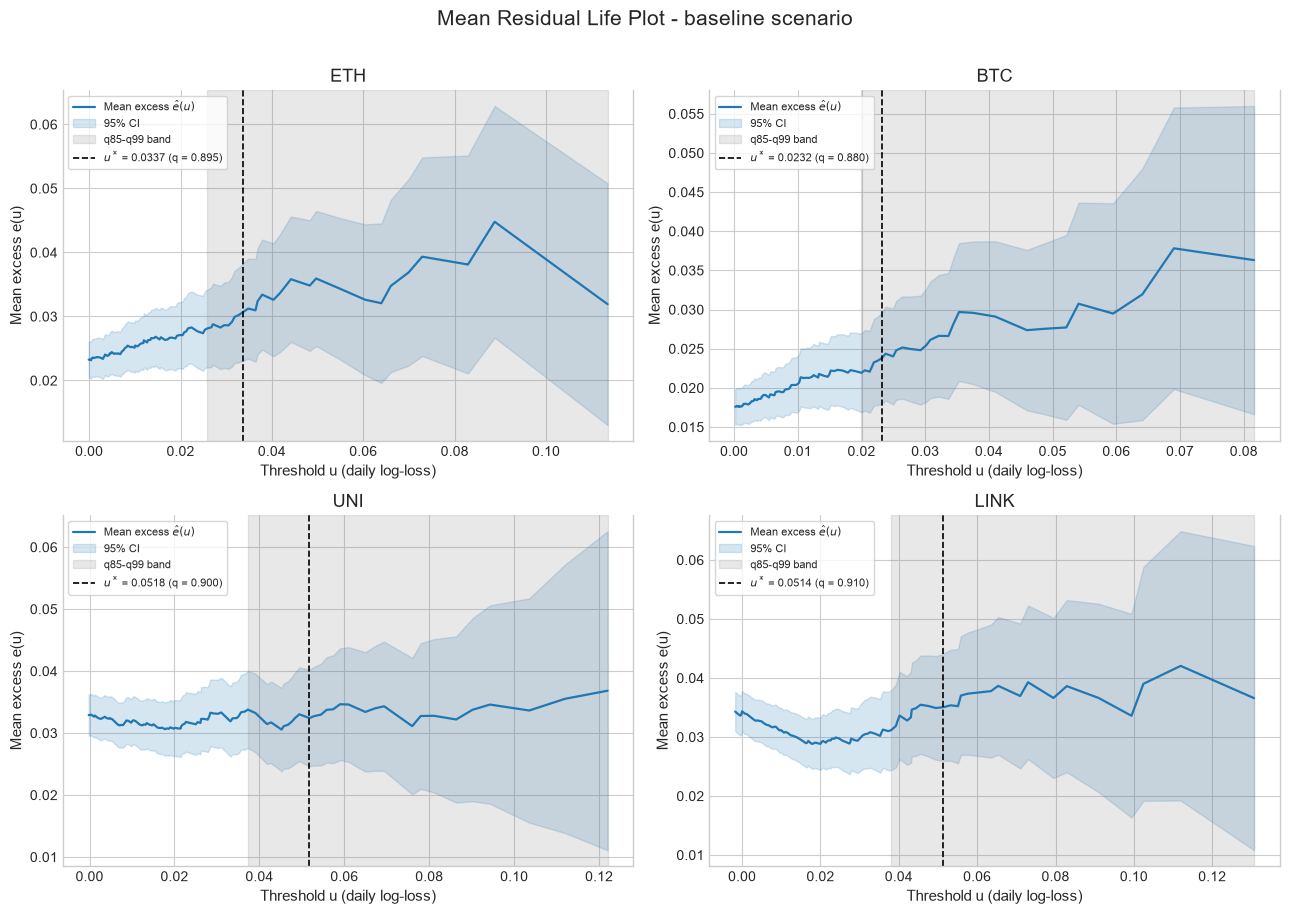

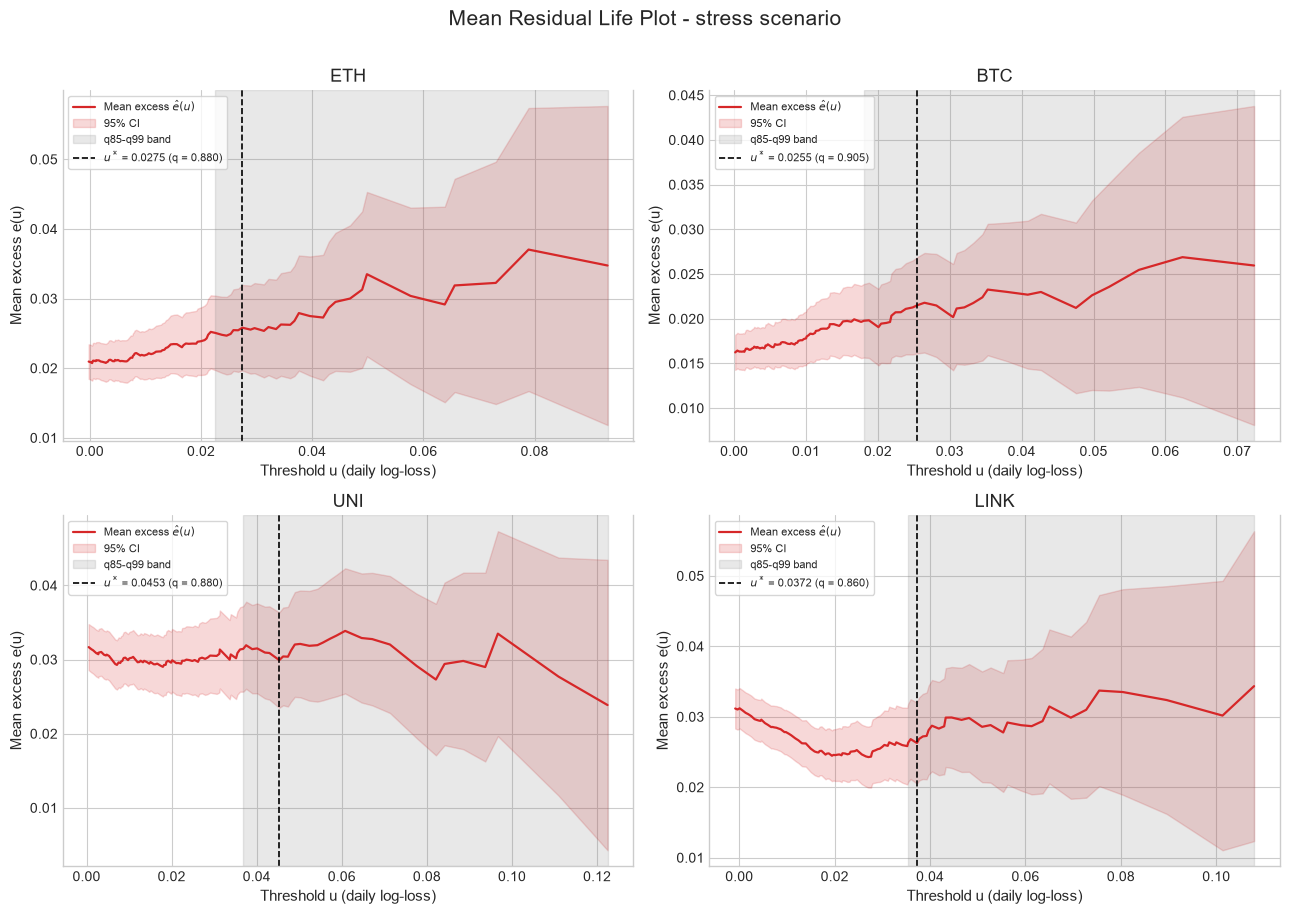

In [78]:
def plot_mean_residual_life(scenario_key: str) -> None:
    """Plot the MRLP of the four assets of one scenario with the threshold band and u*."""
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    color = SCENARIO_COLORS[scenario_key]
    for ax, asset in zip(axes.flat, ASSETS):
        mrl = mrl_tables[scenario_key][asset]
        selection = threshold_selections[scenario_key][asset]
        band_low, band_high = np.quantile(losses[scenario_key][asset], THRESHOLD_BAND)

        ax.plot(mrl["threshold"], mrl["mean_excess"], color=color, lw=1.6, label="Mean excess $\\hat{e}(u)$")
        ax.fill_between(mrl["threshold"], mrl["ci_low"], mrl["ci_high"], color=color, alpha=0.18, label="95% CI")
        ax.axvspan(band_low, band_high, color="grey", alpha=0.18, label=BAND_LABEL)
        ax.axvline(
            selection.threshold, color="black", ls="--", lw=1.2,
            label=f"$u^*$ = {selection.threshold:.4f} (q = {selection.quantile:.3f})",
        )
        ax.set(title=asset, xlabel="Threshold u (daily log-loss)", ylabel="Mean excess e(u)")
        ax.legend(fontsize=8, loc="upper left")

    fig.suptitle(f"Mean Residual Life Plot - {scenario_key} scenario", fontsize=15, y=1.01)
    fig.tight_layout()
    plt.show()


for scenario_key in SCENARIOS:
    plot_mean_residual_life(scenario_key)

## 8. Parameter stability plots

Left column: shape $\hat\xi(u)$ with the zero line separating the Fréchet ($\xi > 0$) and Weibull ($\xi < 0$) domains. Right column: modified scale $\hat\sigma^*(u) = \hat\sigma_u - \hat\xi u$. Both should be flat (within their confidence bands) above a valid threshold.

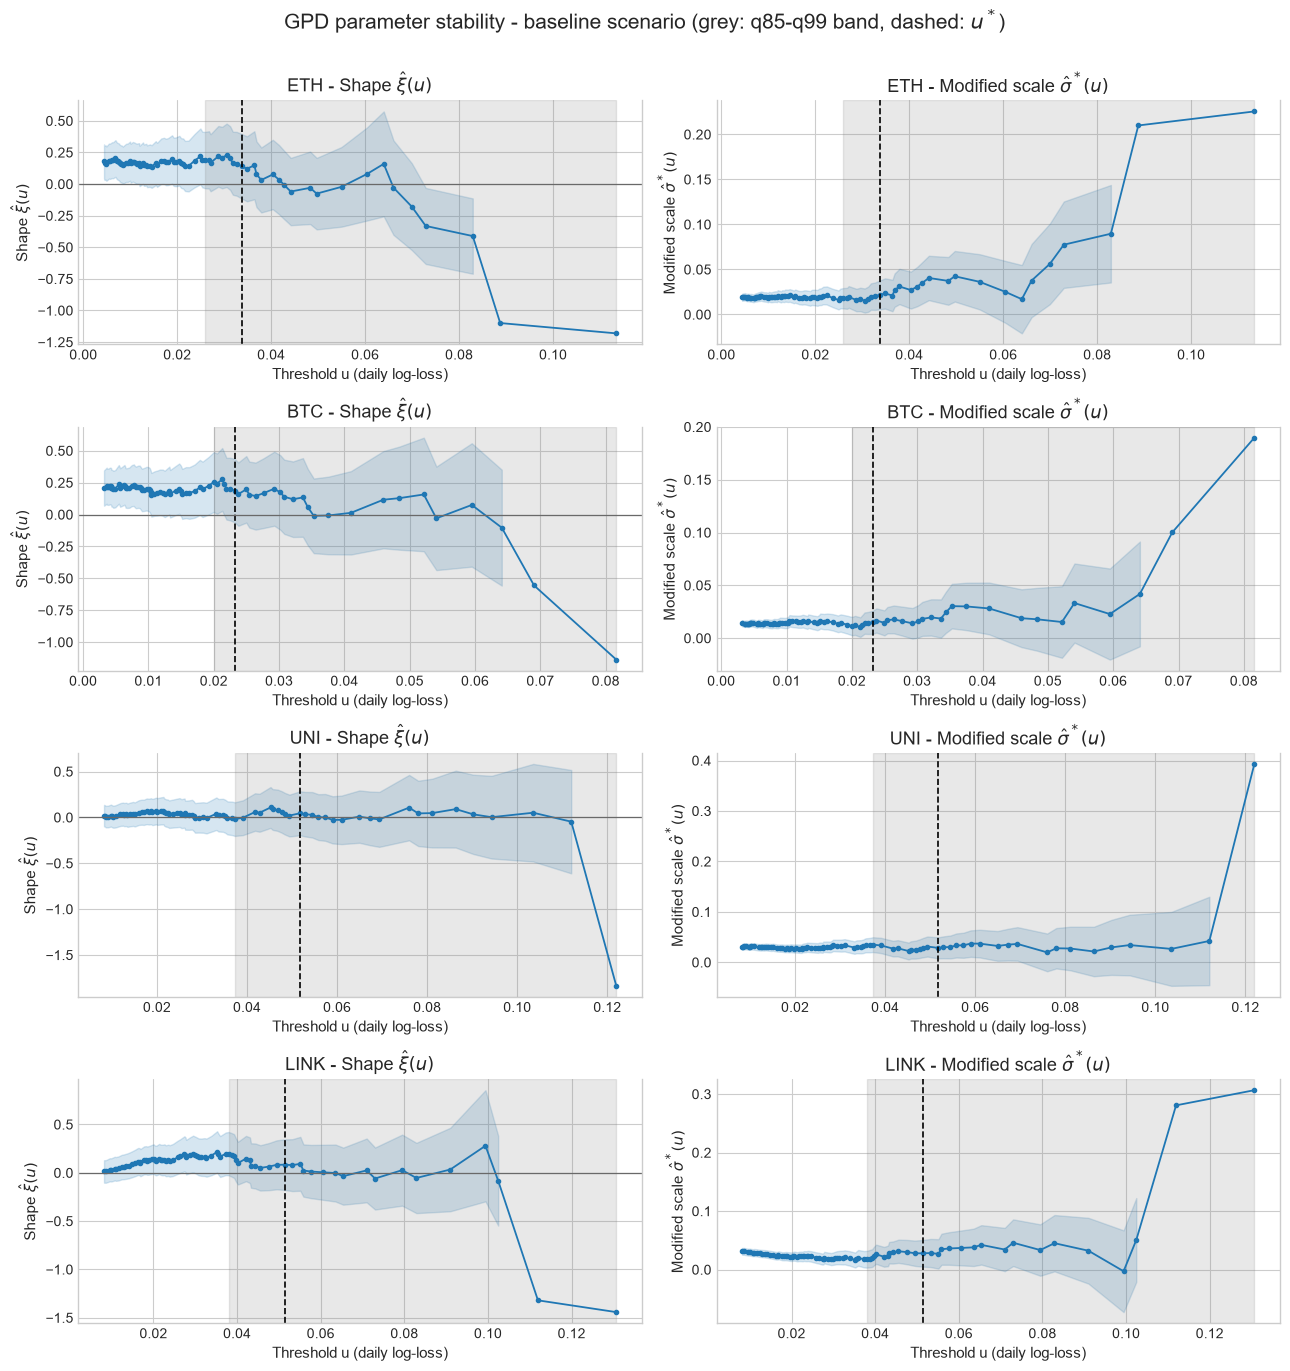

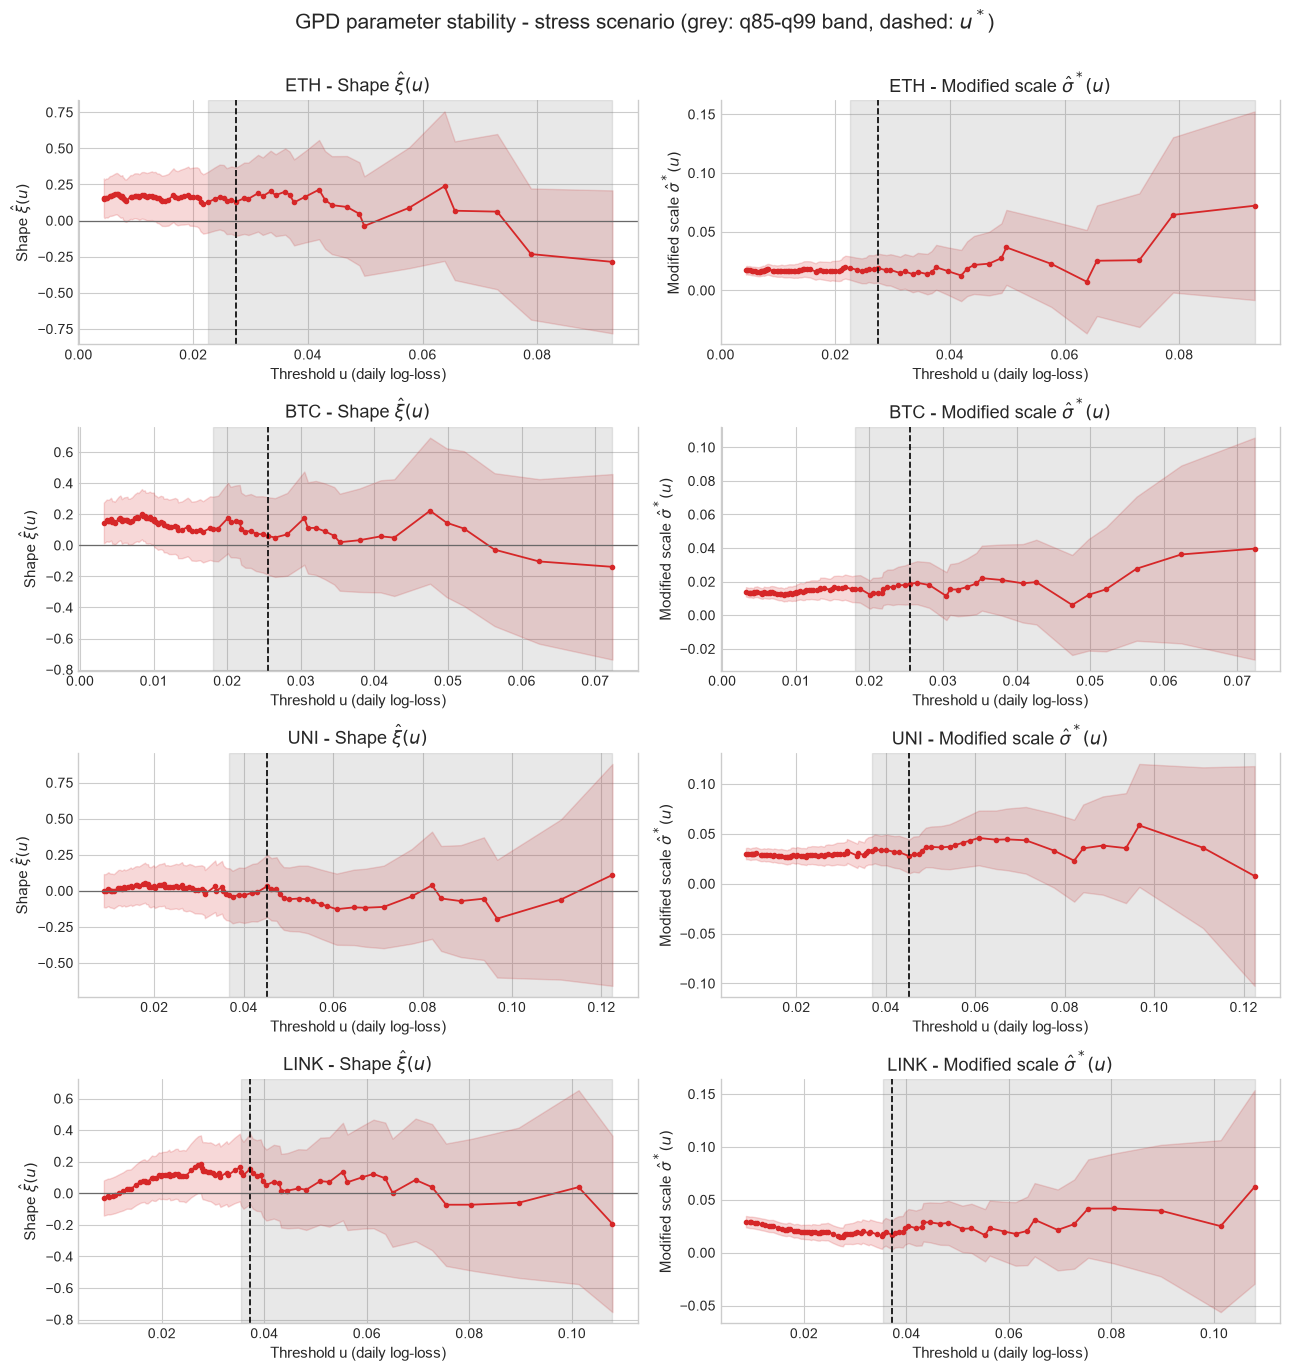

In [79]:
def plot_parameter_stability(scenario_key: str) -> None:
    """Plot xi(u) and sigma*(u) with Wald confidence bands for the four assets of one scenario."""
    fig, axes = plt.subplots(len(ASSETS), 2, figsize=(13, 3.4 * len(ASSETS)), sharex="row")
    color = SCENARIO_COLORS[scenario_key]
    for row, asset in enumerate(ASSETS):
        stability = stability_tables[scenario_key][asset]
        selection = threshold_selections[scenario_key][asset]
        band_low, band_high = np.quantile(losses[scenario_key][asset], THRESHOLD_BAND)
        panels = (
            ("xi", "xi_ci_low", "xi_ci_high", "Shape $\\hat{\\xi}(u)$"),
            ("sigma_star", "sigma_star_ci_low", "sigma_star_ci_high", "Modified scale $\\hat{\\sigma}^*(u)$"),
        )
        for col, (estimate, ci_low, ci_high, label) in enumerate(panels):
            ax = axes[row, col]
            ax.plot(stability["threshold"], stability[estimate], "o-", color=color, ms=3, lw=1.3)
            ax.fill_between(stability["threshold"], stability[ci_low], stability[ci_high], color=color, alpha=0.18)
            ax.axvspan(band_low, band_high, color="grey", alpha=0.18)
            ax.axvline(selection.threshold, color="black", ls="--", lw=1.2)
            if estimate == "xi":
                ax.axhline(0.0, color="dimgrey", lw=0.9)
            ax.set(title=f"{asset} - {label}", xlabel="Threshold u (daily log-loss)", ylabel=label)

    fig.suptitle(
        f"GPD parameter stability - {scenario_key} scenario (grey: {BAND_LABEL}, dashed: $u^*$)",
        fontsize=15, y=1.005,
    )
    fig.tight_layout()
    plt.show()


for scenario_key in SCENARIOS:
    plot_parameter_stability(scenario_key)

## 9. GPD fit at $u^*$ and verification of the heavy-tail condition

The GPD is refitted by MLE on the excesses $Y = X - u^*$ of each asset. The **tail fraction** $\zeta_u = N_u / n$ is stored for the risk measures of Section 11.

Verification of $\xi > 0$ (Fréchet domain, power-law tail) is reported at three levels:

- `xi_positive`: sign of the point estimate;
- `xi_ci_low`, `xi_ci_high`: Wald 95% interval;
- `lrt_pvalue`: one-sided p-value of the signed-root likelihood ratio test of $H_0: \xi = 0$ against $H_1: \xi > 0$.

The shape parameter is deliberately **not constrained** to $\xi > 0$ in the optimizer. If the likelihood peaks at $\xi \le 0$, imposing the constraint would place the estimate on the boundary ($\xi = 0$) and would hide, rather than fix, what the data indicate. Non-positive or non-significant estimates are therefore logged and kept visible in the tables. With 30-110 exceedances, the test has limited power, so a non-significant result means that the sample cannot distinguish a power-law tail from an exponential one; it is not evidence of a thin tail. A fit with $\hat\xi \ge 1$ raises an error, because the mean, and hence the ES, would be infinite.

In [80]:
@dataclass(frozen=True)
class TailModel:
    """Fitted POT/GPD tail model of one asset in one scenario."""

    scenario: str
    asset: str
    n_obs: int
    selection: ThresholdSelection
    excesses: pd.Series
    fit: GPDFit

    @property
    def zeta_u(self) -> float:
        """Empirical probability of exceeding the threshold, N_u / n."""
        return self.fit.n_exceedances / self.n_obs


tail_models: dict[str, dict[str, TailModel]] = {scenario_key: {} for scenario_key in SCENARIOS}
xi_rows: list[dict[str, object]] = []

for scenario_key in SCENARIOS:
    for asset in ASSETS:
        loss = losses[scenario_key][asset]
        selection = threshold_selections[scenario_key][asset]
        excesses = get_exceedances(loss, selection.threshold)
        fit = fit_gpd(excesses.to_numpy())
        if fit is None:
            raise RuntimeError(f"[{scenario_key}] {asset}: GPD MLE failed at u* = {selection.threshold:.5f}")
        if fit.xi >= 1.0:
            raise ValueError(f"[{scenario_key}] {asset}: xi = {fit.xi:.3f} >= 1 implies an infinite mean; ES is undefined")

        model = TailModel(scenario_key, asset, loss.size, selection, excesses, fit)
        tail_models[scenario_key][asset] = model

        cov = gpd_asymptotic_cov(fit)
        xi_se, sigma_se = float(np.sqrt(cov[0, 0])), float(np.sqrt(cov[1, 1]))
        signed_root, lrt_pvalue = xi_zero_lrt(excesses.to_numpy(), fit)
        xi_positive = fit.xi > 0
        xi_significant = lrt_pvalue < 1 - CI_LEVEL

        if not xi_positive:
            logger.warning(
                "[%s] %s: xi = %.4f <= 0 at u* (q=%.3f); heavy-tail (Frechet) condition NOT met",
                scenario_key, asset, fit.xi, selection.quantile,
            )
        elif not xi_significant:
            logger.info(
                "[%s] %s: xi = %.4f > 0 but not significantly different from 0 (LRT p = %.3f)",
                scenario_key, asset, fit.xi, lrt_pvalue,
            )

        xi_rows.append(
            {
                "scenario": scenario_key,
                "asset": asset,
                "zeta_u": model.zeta_u,
                "xi": fit.xi,
                "xi_se": xi_se,
                "xi_ci_low": fit.xi - Z_CRIT * xi_se,
                "xi_ci_high": fit.xi + Z_CRIT * xi_se,
                "sigma": fit.sigma,
                "sigma_se": sigma_se,
                "log_likelihood": fit.log_likelihood,
                "lrt_signed_root": signed_root,
                "lrt_pvalue": lrt_pvalue,
                "xi_positive": xi_positive,
                "xi_significant": xi_significant,
                "tail_domain": "Frechet (heavy)" if xi_positive else "Gumbel/Weibull (light/bounded)",
            }
        )

xi_verification_df = pd.DataFrame(xi_rows).set_index(["scenario", "asset"])
display(
    xi_verification_df.join(threshold_selection_df[["u_star", "n_exceedances"]])
    .style.format(precision=4)
    .set_caption("GPD MLE at u* and verification of xi > 0")
)
print(
    f"xi > 0 in {int(xi_verification_df['xi_positive'].sum())}/{len(xi_verification_df)} fits; "
    f"significant at {1 - CI_LEVEL:.0%} in {int(xi_verification_df['xi_significant'].sum())}/{len(xi_verification_df)}"
)

INFO | evt_gpd | [baseline] ETH: xi = 0.1408 > 0 but not significantly different from 0 (LRT p = 0.157)
INFO | evt_gpd | [baseline] BTC: xi = 0.1878 > 0 but not significantly different from 0 (LRT p = 0.059)
INFO | evt_gpd | [baseline] UNI: xi = 0.0452 > 0 but not significantly different from 0 (LRT p = 0.361)
INFO | evt_gpd | [baseline] LINK: xi = 0.0842 > 0 but not significantly different from 0 (LRT p = 0.277)
INFO | evt_gpd | [stress] ETH: xi = 0.1298 > 0 but not significantly different from 0 (LRT p = 0.117)
INFO | evt_gpd | [stress] BTC: xi = 0.0607 > 0 but not significantly different from 0 (LRT p = 0.308)
INFO | evt_gpd | [stress] UNI: xi = 0.0330 > 0 but not significantly different from 0 (LRT p = 0.397)
INFO | evt_gpd | [stress] LINK: xi = 0.1544 > 0 but not significantly different from 0 (LRT p = 0.085)


xi > 0 in 8/8 fits; significant at 5% in 0/8


## 10. Goodness of fit: Q-Q plots and Anderson-Darling test

**Q-Q plot.** The ordered empirical excesses $y_{(1)} \le \dots \le y_{(N_u)}$ are plotted against the theoretical GPD quantiles $G^{-1}_{\hat\xi,\hat\sigma}(p_i)$ at the plotting positions $p_i = (i - 0.5)/N_u$. Points on the 45° line indicate a good fit; systematic upward departures at the right end indicate an underestimated tail.

**Anderson-Darling test.** The statistic weights discrepancies by $[F(1-F)]^{-1}$, which penalizes deviations in the tails far more than Kolmogorov-Smirnov:

$$
A^2 = -N_u - \frac{1}{N_u}\sum_{i=1}^{N_u} (2i - 1)\left[\ln G\!\left(y_{(i)}\right) + \ln\!\left(1 - G\!\left(y_{(N_u + 1 - i)}\right)\right)\right]
$$

Because $(\xi, \sigma)$ are estimated from the same data, the standard $A^2$ critical values (valid only for a fully specified null) would be far too conservative. The p-value is therefore obtained by a **parametric bootstrap** with re-estimation: simulate $N_u$ excesses from $G_{\hat\xi,\hat\sigma}$, refit the GPD, recompute $A^{2*}$, and set $p = \left(1 + \#\{A^{2*}_b \ge A^2\}\right) / (B + 1)$ with $B$ = `N_BOOTSTRAP_AD`. $H_0$ (the excesses follow a GPD) is not rejected when $p \ge 0.05$.

In [81]:
def anderson_darling_statistic(excesses: np.ndarray, xi: float, sigma: float) -> float:
    """Anderson-Darling A^2 of the excesses against a GPD(xi, sigma) with zero location."""
    ordered = np.sort(np.asarray(excesses, dtype=float))
    n = ordered.size
    cdf = np.clip(genpareto.cdf(ordered, xi, loc=0.0, scale=sigma), CDF_CLIP, 1.0 - CDF_CLIP)
    weights = 2.0 * np.arange(1, n + 1) - 1.0
    return float(-n - np.mean(weights * (np.log(cdf) + np.log1p(-cdf[::-1]))))


def anderson_darling_test(
    excesses: np.ndarray, fit: GPDFit, n_boot: int, rng: np.random.Generator
) -> dict[str, float]:
    """Anderson-Darling GPD test with a parametric-bootstrap p-value that accounts for estimated parameters."""
    excesses = np.asarray(excesses, dtype=float)
    a2_observed = anderson_darling_statistic(excesses, fit.xi, fit.sigma)

    a2_bootstrap = np.full(n_boot, np.nan)
    for b in range(n_boot):
        simulated = genpareto.rvs(fit.xi, loc=0.0, scale=fit.sigma, size=excesses.size, random_state=rng)
        refit = fit_gpd(simulated)
        if refit is not None:
            a2_bootstrap[b] = anderson_darling_statistic(simulated, refit.xi, refit.sigma)

    valid = a2_bootstrap[np.isfinite(a2_bootstrap)]
    if valid.size < 0.95 * n_boot:
        logger.warning("Anderson-Darling bootstrap: only %d/%d valid replicates", valid.size, n_boot)
    p_value = (1.0 + np.sum(valid >= a2_observed)) / (valid.size + 1.0)
    return {
        "ad_statistic": a2_observed,
        "ad_pvalue": float(p_value),
        "ad_critical_5pct": float(np.quantile(valid, 0.95)),
        "ad_n_valid": int(valid.size),
    }


gof_rows: list[dict[str, object]] = []
for scenario_key in SCENARIOS:
    for asset in ASSETS:
        model = tail_models[scenario_key][asset]
        result = anderson_darling_test(
            model.excesses.to_numpy(), model.fit, N_BOOTSTRAP_AD, make_rng(scenario_key, asset, "anderson_darling")
        )
        if result["ad_pvalue"] < 1 - CI_LEVEL:
            logger.warning(
                "[%s] %s: Anderson-Darling rejects the GPD at 5%% (A2 = %.3f, p = %.3f)",
                scenario_key, asset, result["ad_statistic"], result["ad_pvalue"],
            )
        gof_rows.append({"scenario": scenario_key, "asset": asset, **result})

gof_df = pd.DataFrame(gof_rows).set_index(["scenario", "asset"])
gof_df["gpd_not_rejected"] = gof_df["ad_pvalue"] >= 1 - CI_LEVEL
display(gof_df.style.format(precision=4).set_caption("Anderson-Darling goodness of fit (parametric bootstrap)"))

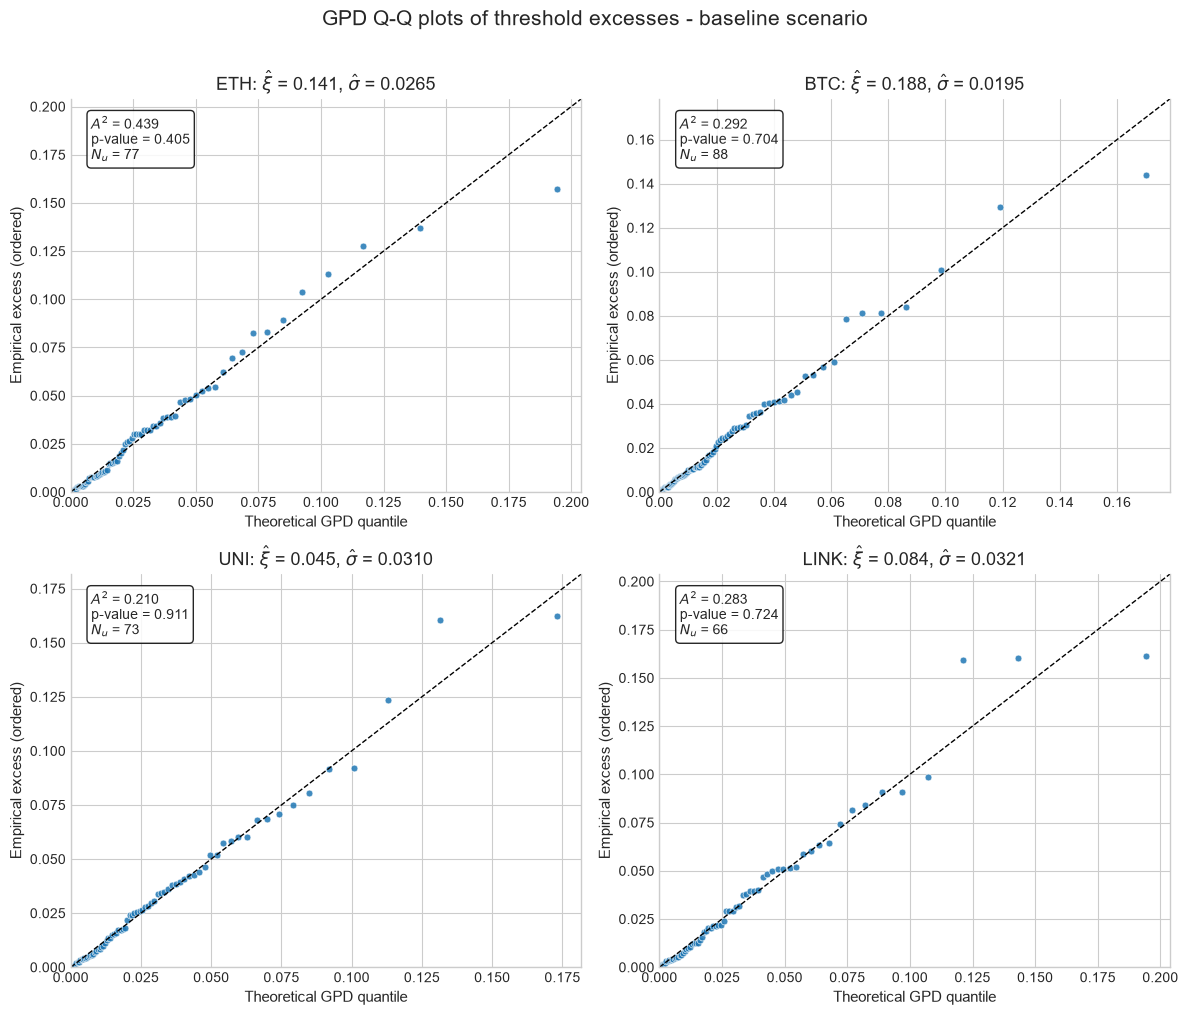

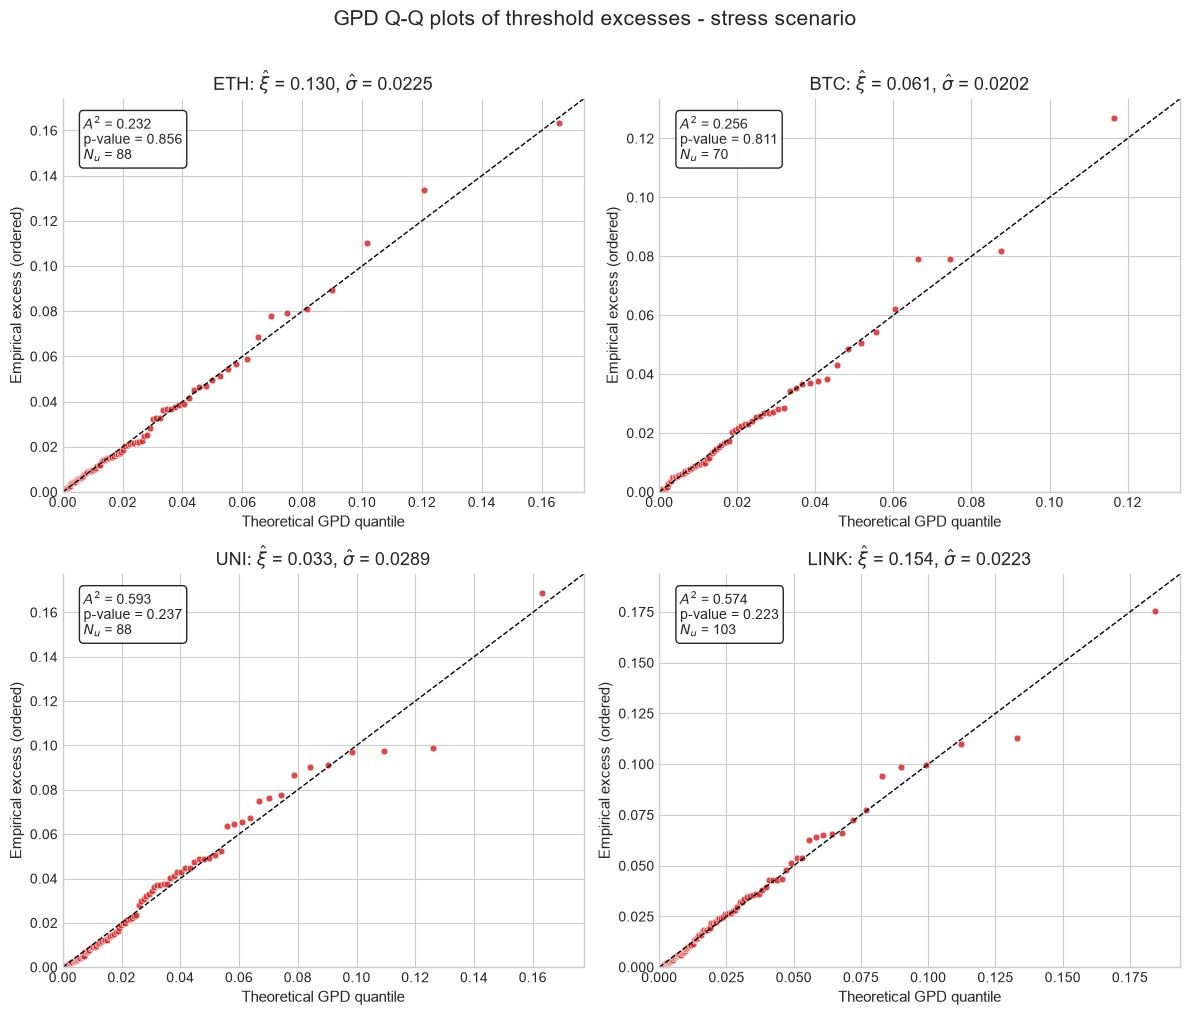

In [82]:
def plot_gpd_qq(scenario_key: str) -> None:
    """Q-Q plot of ordered empirical excesses against fitted GPD quantiles for one scenario."""
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    color = SCENARIO_COLORS[scenario_key]
    for ax, asset in zip(axes.flat, ASSETS):
        model = tail_models[scenario_key][asset]
        empirical = np.sort(model.excesses.to_numpy())
        n = empirical.size
        plotting_positions = (np.arange(1, n + 1) - 0.5) / n
        theoretical = genpareto.ppf(plotting_positions, model.fit.xi, loc=0.0, scale=model.fit.sigma)
        upper = 1.05 * max(empirical.max(), theoretical.max())

        ax.scatter(theoretical, empirical, s=24, color=color, alpha=0.85, edgecolor="white", linewidth=0.5)
        ax.plot([0, upper], [0, upper], color="black", ls="--", lw=1)
        gof = gof_df.loc[(scenario_key, asset)]
        ax.text(
            0.04, 0.96,
            f"$A^2$ = {gof['ad_statistic']:.3f}\np-value = {gof['ad_pvalue']:.3f}\n$N_u$ = {n}",
            transform=ax.transAxes, va="top", fontsize=10,
            bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.85},
        )
        ax.set(
            xlim=(0, upper), ylim=(0, upper),
            title=f"{asset}: $\\hat\\xi$ = {model.fit.xi:.3f}, $\\hat\\sigma$ = {model.fit.sigma:.4f}",
            xlabel="Theoretical GPD quantile", ylabel="Empirical excess (ordered)",
        )

    fig.suptitle(f"GPD Q-Q plots of threshold excesses - {scenario_key} scenario", fontsize=15, y=1.01)
    fig.tight_layout()
    plt.show()


for scenario_key in SCENARIOS:
    plot_gpd_qq(scenario_key)

## 11. Value-at-Risk and Expected Shortfall

Combining the empirical tail fraction $\zeta_u = N_u / n$ with the GPD for the excesses gives the tail estimator $\bar F(x) = \zeta_u \left(1 + \xi (x - u)/\sigma\right)^{-1/\xi}$ for $x > u$. Inverting at level $p$ (valid when $1 - p < \zeta_u$):

$$
VaR_p = u + \frac{\sigma}{\xi}\left[\left(\frac{1 - p}{\zeta_u}\right)^{-\xi} - 1\right] \qquad \left(\xi \to 0:\; VaR_p = u - \sigma \ln\frac{1 - p}{\zeta_u}\right)
$$

By the threshold-stability property, the excess over $VaR_p$ is again GPD with shape $\xi$ and scale $\sigma + \xi(VaR_p - u)$, whose mean is $\frac{\sigma + \xi (VaR_p - u)}{1 - \xi}$. Hence, for $\xi < 1$:

$$
ES_p = \mathbb{E}[X \mid X > VaR_p] = VaR_p + \frac{\sigma + \xi (VaR_p - u)}{1 - \xi} = \frac{VaR_p}{1 - \xi} + \frac{\sigma - \xi u}{1 - \xi}
$$

Two complementary figures are reported:

- `es_price_drop`: the ES expressed as an **arithmetic price decline**, $\mathbb{E}[1 - e^{-X} \mid X > VaR_p] = 1 - e^{-VaR_p}\,\mathbb{E}[e^{-Z}]$ with $Z \sim GPD(\xi, \sigma + \xi(VaR_p - u))$, computed by numerical integration. This is the quantity to apply as a collateral price shock. Because of Jensen's inequality it is **not** equal to $1 - e^{-ES_p}$.
- `var_empirical`, `es_empirical`: historical-simulation benchmarks. With $n \approx 730$, only about 7 observations lie beyond the empirical 99% quantile, which is exactly why a parametric tail model is needed.

In [83]:
def gpd_value_at_risk(threshold: float, xi: float, sigma: float, zeta_u: float, p: float) -> float:
    """POT tail-estimator VaR_p of the loss distribution.

    Raises:
        ValueError: If zeta_u is not in (0, 1) or p does not lie beyond the threshold (1 - p >= zeta_u).
    """
    if not 0.0 < zeta_u < 1.0:
        raise ValueError(f"zeta_u must lie in (0, 1), got {zeta_u}")
    tail_ratio = (1.0 - p) / zeta_u
    if tail_ratio >= 1.0:
        raise ValueError(f"p = {p} must exceed the threshold non-exceedance level 1 - zeta_u = {1.0 - zeta_u:.4f}")
    if abs(xi) < XI_ZERO_TOL:
        return float(threshold - sigma * np.log(tail_ratio))
    return float(threshold + sigma / xi * (tail_ratio ** (-xi) - 1.0))


def gpd_expected_shortfall(threshold: float, xi: float, sigma: float, zeta_u: float, p: float) -> float:
    """POT tail-estimator ES_p = E[X | X > VaR_p] of the loss distribution.

    Raises:
        ValueError: If xi >= 1 (infinite mean) or VaR_p is undefined.
    """
    if xi >= 1.0:
        raise ValueError(f"ES is infinite for xi >= 1 (xi = {xi:.4f})")
    value_at_risk = gpd_value_at_risk(threshold, xi, sigma, zeta_u, p)
    return float((value_at_risk + sigma - xi * threshold) / (1.0 - xi))


def gpd_expected_price_drop(threshold: float, xi: float, sigma: float, zeta_u: float, p: float) -> float:
    """Expected arithmetic price decline E[1 - exp(-X) | X > VaR_p] under the fitted tail."""
    value_at_risk = gpd_value_at_risk(threshold, xi, sigma, zeta_u, p)
    beyond_var_scale = sigma + xi * (value_at_risk - threshold)
    discount_factor = genpareto.expect(lambda z: np.exp(-z), args=(xi,), loc=0.0, scale=beyond_var_scale)
    return float(1.0 - np.exp(-value_at_risk) * discount_factor)


def empirical_tail_risk(loss: pd.Series, p: float) -> tuple[float, float, int]:
    """Historical-simulation VaR_p, ES_p and the number of observations at or beyond VaR_p."""
    values = loss.to_numpy()
    value_at_risk = float(np.quantile(values, p))
    tail = values[values >= value_at_risk]
    return value_at_risk, float(tail.mean()), int(tail.size)


risk_rows: list[dict[str, object]] = []
for scenario_key in SCENARIOS:
    for asset in ASSETS:
        model = tail_models[scenario_key][asset]
        params = (model.selection.threshold, model.fit.xi, model.fit.sigma, model.zeta_u, CONFIDENCE_LEVEL)
        var_empirical, es_empirical, n_tail_empirical = empirical_tail_risk(losses[scenario_key][asset], CONFIDENCE_LEVEL)
        risk_rows.append(
            {
                "scenario": scenario_key,
                "asset": asset,
                "var": gpd_value_at_risk(*params),
                "es": gpd_expected_shortfall(*params),
                "es_price_drop": gpd_expected_price_drop(*params),
                "var_empirical": var_empirical,
                "es_empirical": es_empirical,
                "n_tail_empirical": n_tail_empirical,
            }
        )

risk_df = pd.DataFrame(risk_rows).set_index(["scenario", "asset"])
display(
    risk_df.style.format(precision=4)
    .format({"es_price_drop": "{:.2%}"})
    .set_caption(f"GPD-POT risk measures at p = {CONFIDENCE_LEVEL} (daily log-loss units)")
)

## 12. Bootstrap confidence interval for $ES_{0.99}$

The point estimate of $ES_{0.99}$ extrapolates beyond the data and is sensitive to $\hat\xi$. Its sampling uncertainty is quantified by a **nonparametric bootstrap over the excesses** with $B$ = `N_BOOTSTRAP_ES` replicates:

1. Resample the $N_u$ excesses with replacement, holding $u^*$ and $\zeta_u$ fixed.
2. Refit the GPD by MLE, giving $(\xi^*_b, \sigma^*_b)$.
3. Recompute $ES^*_{0.99,b}$ with the closed form of Section 11.

The 95% interval is the percentile interval $[q_{0.025}, q_{0.975}]$ of $\{ES^*_b\}$. Replicates with $\xi^*_b \ge 1$ (infinite ES) or failed fits are discarded and counted. The share of replicates with $\xi^*_b > 0$ (`boot_xi_positive_share`) provides a direct bootstrap measure of how firmly the data support a Fréchet tail. The histograms below are drawn over the central 99% of the replicates, because a few resamples with $\xi^*$ close to 1 produce extreme ES values that would otherwise flatten the plot.

This interval is a **lower bound** on the true uncertainty: it ignores the randomness of $u^*$ and $\zeta_u$, and i.i.d. resampling ignores the volatility clustering of daily crypto returns.

In [84]:
def bootstrap_expected_shortfall(
    model: TailModel, p: float, n_boot: int, rng: np.random.Generator
) -> pd.DataFrame:
    """Nonparametric bootstrap of (xi, sigma, ES_p) obtained by resampling the excesses at a fixed u* and zeta_u."""
    excesses = model.excesses.to_numpy()
    replicates = np.full((n_boot, 3), np.nan)
    for b in range(n_boot):
        resample = rng.choice(excesses, size=excesses.size, replace=True)
        fit = fit_gpd(resample)
        if fit is None:
            continue
        replicates[b, :2] = fit.xi, fit.sigma
        if fit.xi < 1.0:
            replicates[b, 2] = gpd_expected_shortfall(model.selection.threshold, fit.xi, fit.sigma, model.zeta_u, p)
    return pd.DataFrame(replicates, columns=["xi", "sigma", "es"])


bootstrap_replicates: dict[str, dict[str, pd.DataFrame]] = {scenario_key: {} for scenario_key in SCENARIOS}
bootstrap_rows: list[dict[str, object]] = []
alpha = 1.0 - CI_LEVEL

for scenario_key in SCENARIOS:
    for asset in ASSETS:
        replicates = bootstrap_expected_shortfall(
            tail_models[scenario_key][asset], CONFIDENCE_LEVEL, N_BOOTSTRAP_ES, make_rng(scenario_key, asset, "es_bootstrap")
        )
        bootstrap_replicates[scenario_key][asset] = replicates
        valid_es = replicates["es"].dropna()
        if valid_es.size < 0.95 * N_BOOTSTRAP_ES:
            logger.warning(
                "[%s] %s: only %d/%d valid ES bootstrap replicates", scenario_key, asset, valid_es.size, N_BOOTSTRAP_ES
            )
        bootstrap_rows.append(
            {
                "scenario": scenario_key,
                "asset": asset,
                "es_ci_low": valid_es.quantile(alpha / 2),
                "es_ci_high": valid_es.quantile(1.0 - alpha / 2),
                "es_boot_se": valid_es.std(ddof=1),
                "boot_xi_positive_share": float((replicates["xi"].dropna() > 0).mean()),
                "boot_n_valid": int(valid_es.size),
            }
        )

bootstrap_summary_df = pd.DataFrame(bootstrap_rows).set_index(["scenario", "asset"])
display(
    bootstrap_summary_df.join(risk_df[["es"]])
    .style.format(precision=4)
    .format({"boot_xi_positive_share": "{:.1%}"})
    .set_caption(f"Bootstrap {CI_LEVEL:.0%} percentile CI for ES (B = {N_BOOTSTRAP_ES})")
)

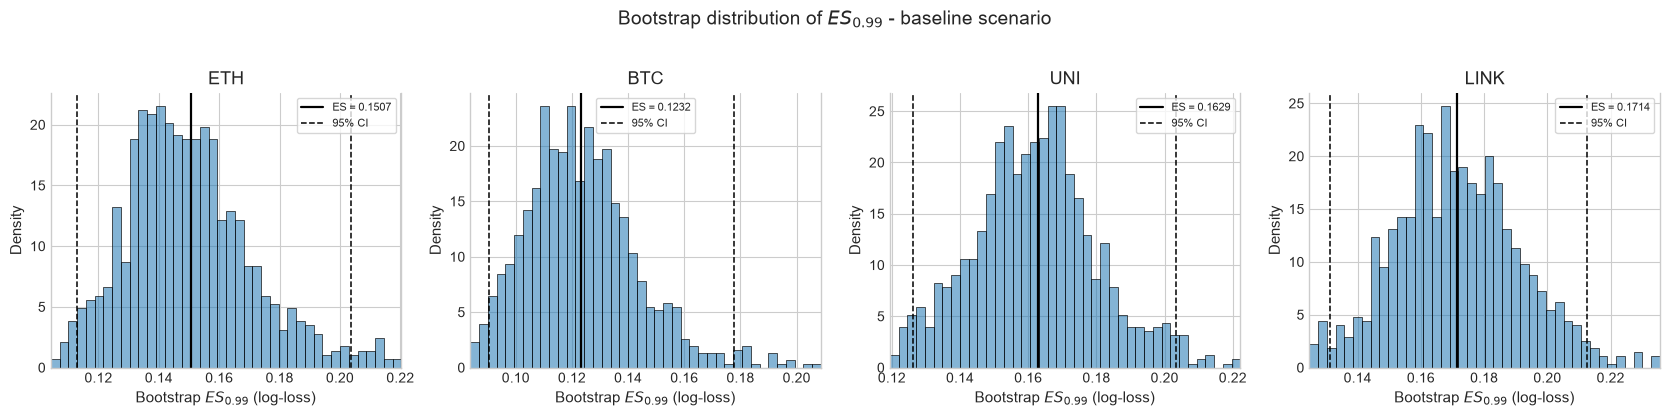

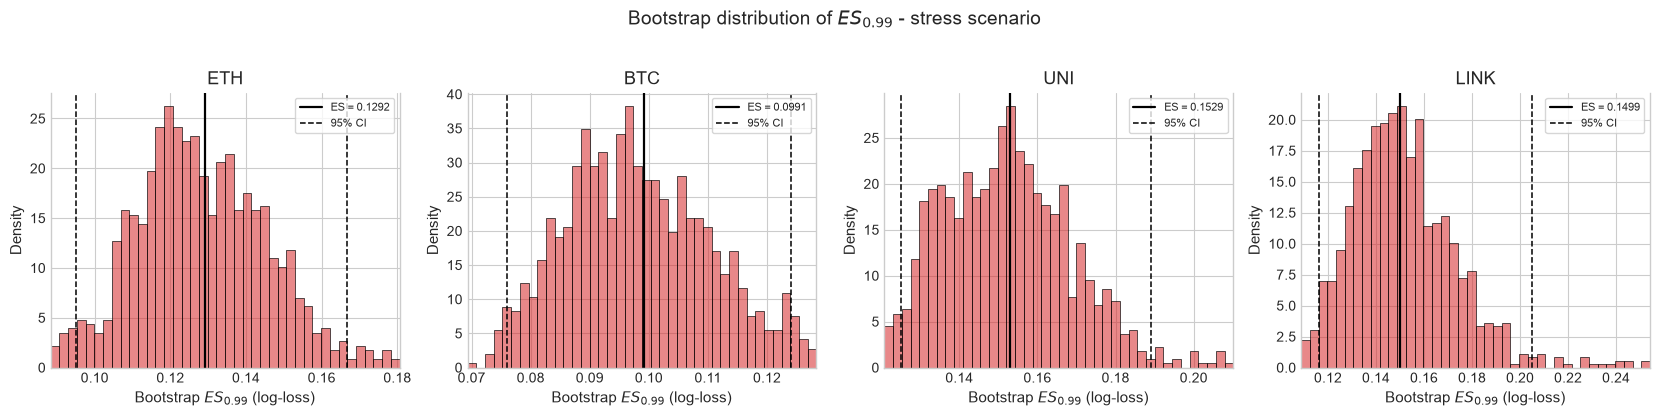

In [85]:
def plot_bootstrap_distribution(scenario_key: str) -> None:
    """Histogram of bootstrap ES replicates with the point estimate and the percentile CI."""
    fig, axes = plt.subplots(1, len(ASSETS), figsize=(4.2 * len(ASSETS), 4))
    color = SCENARIO_COLORS[scenario_key]
    for ax, asset in zip(axes, ASSETS):
        es_replicates = bootstrap_replicates[scenario_key][asset]["es"].dropna()
        summary = bootstrap_summary_df.loc[(scenario_key, asset)]
        point = risk_df.loc[(scenario_key, asset), "es"]

        view_low, view_high = es_replicates.quantile([0.005, 0.995])

        sns.histplot(es_replicates, bins=40, binrange=(view_low, view_high), color=color, alpha=0.55, ax=ax, stat="density")
        ax.axvline(point, color="black", lw=1.6, label=f"ES = {point:.4f}")
        ax.axvline(summary["es_ci_low"], color="black", ls="--", lw=1.1, label=f"{CI_LEVEL:.0%} CI")
        ax.axvline(summary["es_ci_high"], color="black", ls="--", lw=1.1)
        ax.set(
            title=asset,
            xlim=(view_low, view_high),
            xlabel=f"Bootstrap $ES_{{{CONFIDENCE_LEVEL}}}$ (log-loss)",
            ylabel="Density",
        )
        ax.legend(fontsize=8)

    fig.suptitle(f"Bootstrap distribution of $ES_{{{CONFIDENCE_LEVEL}}}$ - {scenario_key} scenario", fontsize=14, y=1.03)
    fig.tight_layout()
    plt.show()


for scenario_key in SCENARIOS:
    plot_bootstrap_distribution(scenario_key)

## 13. Consolidated tail-parameter tables

All outputs are merged into a single DataFrame per scenario, `evt_results[scenario]`, indexed by asset. The **headline view** shows the core tail parameters (threshold $u^*$, shape $\xi$, scale $\sigma$, $ES_{0.99}$ with its bootstrap CI). The **full view** adds the inference and goodness-of-fit diagnostics.

In [86]:
HEADLINE_LABELS: dict[str, str] = {
    "u_star": "Threshold u*",
    "threshold_quantile": "u* quantile",
    "n_exceedances": "N_u",
    "xi": "Shape ξ",
    "sigma": "Scale σ",
    "var": f"VaR {CONFIDENCE_LEVEL}",
    "es": f"ES {CONFIDENCE_LEVEL}",
    "es_ci_low": f"ES {CI_LEVEL:.0%} CI low",
    "es_ci_high": f"ES {CI_LEVEL:.0%} CI high",
    "es_price_drop": "ES as price drop",
    "xi_positive": "ξ > 0",
    "ad_pvalue": "AD p-value",
}


def build_scenario_table(scenario_key: str) -> pd.DataFrame:
    """Merge threshold, GPD fit, goodness-of-fit, risk and bootstrap outputs of one scenario."""
    components = [threshold_selection_df, xi_verification_df, gof_df, risk_df, bootstrap_summary_df]
    table = pd.concat([frame.xs(scenario_key, level="scenario") for frame in components], axis=1)
    if table.columns.duplicated().any():
        raise ValueError(f"Duplicated result columns: {table.columns[table.columns.duplicated()].tolist()}")
    table.insert(0, "confidence_level", CONFIDENCE_LEVEL)
    return table.loc[ASSETS]


def style_headline(table: pd.DataFrame, scenario_key: str) -> "pd.io.formats.style.Styler":
    """Format the headline parameter view of one scenario for display."""
    headline = table[list(HEADLINE_LABELS)].rename(columns=HEADLINE_LABELS)
    return (
        headline.style.format(precision=4)
        .format({HEADLINE_LABELS["threshold_quantile"]: "{:.3f}", HEADLINE_LABELS["es_price_drop"]: "{:.2%}"})
        .background_gradient(subset=[HEADLINE_LABELS["es"]], cmap="Reds")
        .set_caption(f"GPD-POT tail parameters - {scenario_key} scenario (daily log-loss units)")
        .set_table_styles([{"selector": "caption", "props": "font-size: 14px; font-weight: bold;"}])
    )


evt_results: dict[str, pd.DataFrame] = {scenario_key: build_scenario_table(scenario_key) for scenario_key in SCENARIOS}

for scenario_key in SCENARIOS:
    display(style_headline(evt_results[scenario_key], scenario_key))

,Threshold u*,u* quantile,N_u,Shape ξ,Scale σ,VaR 0.99,ES 0.99,ES 95% CI low,ES 95% CI high,ES as price drop,ξ > 0,AD p-value
asset,,,,,,,,,,,,
ETH,0.033706,0.895,77,0.140813,0.026492,0.107718,0.150682,0.113042,0.203694,13.88%,True,0.405000
BTC,0.023204,0.880,88,0.187819,0.019452,0.084942,0.123170,0.090643,0.177654,11.49%,True,0.704000
UNI,0.051775,0.900,73,0.045223,0.030955,0.126895,0.162875,0.126098,0.203251,14.97%,True,0.911000
LINK,0.051362,0.910,66,0.084193,0.032140,0.129110,0.171352,0.131127,0.212453,15.66%,True,0.724000


,Threshold u*,u* quantile,N_u,Shape ξ,Scale σ,VaR 0.99,ES 0.99,ES 95% CI low,ES 95% CI high,ES as price drop,ξ > 0,AD p-value
asset,,,,,,,,,,,,
ETH,0.027450,0.880,88,0.129825,0.022486,0.093532,0.129232,0.095097,0.166627,12.05%,True,0.856000
BTC,0.025491,0.905,70,0.060656,0.020207,0.074452,0.099125,0.076043,0.124048,9.41%,True,0.811000
UNI,0.045296,0.880,88,0.032974,0.028935,0.120368,0.152850,0.124975,0.189046,14.13%,True,0.237000
LINK,0.037240,0.860,103,0.154435,0.022302,0.110160,0.149854,0.116382,0.205159,13.82%,True,0.223000


In [87]:
for scenario_key in SCENARIOS:
    display(
        evt_results[scenario_key]
        .style.format(precision=4)
        .set_caption(f"Full EVT diagnostics - {scenario_key} scenario")
    )

,confidence_level,threshold_quantile,u_star,n_exceedances,xi_local_std,selection_method,zeta_u,xi,xi_se,xi_ci_low,xi_ci_high,sigma,sigma_se,log_likelihood,lrt_signed_root,lrt_pvalue,xi_positive,xi_significant,tail_domain,ad_statistic,ad_pvalue,ad_critical_5pct,ad_n_valid,gpd_not_rejected,var,es,es_price_drop,var_empirical,es_empirical,n_tail_empirical,es_ci_low,es_ci_high,es_boot_se,boot_xi_positive_share,boot_n_valid
asset,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
ETH,0.9900,0.8950,0.0337,77,0.0174,stability_xi_positive,0.1055,0.1408,0.1300,-0.1140,0.3956,0.0265,0.0046,191.7356,1.0075,0.1568,True,False,Frechet (heavy),0.4389,0.4050,1.0172,999,True,0.1077,0.1507,0.1388,0.1135,0.1454,8,0.1130,0.2037,0.0219,0.8110,1000
BTC,0.9900,0.8800,0.0232,88,0.0173,stability_xi_positive,0.1205,0.1878,0.1266,-0.0604,0.4360,0.0195,0.0032,242.1745,1.5638,0.0589,True,False,Frechet (heavy),0.2915,0.7040,0.9128,999,True,0.0849,0.1232,0.1149,0.0816,0.1179,8,0.0906,0.1777,0.0214,0.9160,1000
UNI,0.9900,0.9000,0.0518,73,0.0099,stability_xi_positive,0.1000,0.0452,0.1223,-0.1945,0.2850,0.0310,0.0052,177.3907,0.3565,0.3607,True,False,Frechet (heavy),0.2101,0.9110,1.0547,999,True,0.1269,0.1629,0.1497,0.1220,0.1588,8,0.1261,0.2033,0.0192,0.6110,1000
LINK,0.9900,0.9100,0.0514,66,0.0104,stability_xi_positive,0.0904,0.0842,0.1335,-0.1774,0.3458,0.0321,0.0058,155.3288,0.5910,0.2773,True,False,Frechet (heavy),0.2829,0.7240,0.9263,999,True,0.1291,0.1714,0.1566,0.1307,0.1673,8,0.1311,0.2125,0.0204,0.6770,1000


,confidence_level,threshold_quantile,u_star,n_exceedances,xi_local_std,selection_method,zeta_u,xi,xi_se,xi_ci_low,xi_ci_high,sigma,sigma_se,log_likelihood,lrt_signed_root,lrt_pvalue,xi_positive,xi_significant,tail_domain,ad_statistic,ad_pvalue,ad_critical_5pct,ad_n_valid,gpd_not_rejected,var,es,es_price_drop,var_empirical,es_empirical,n_tail_empirical,es_ci_low,es_ci_high,es_boot_se,boot_xi_positive_share,boot_n_valid
asset,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
ETH,0.9900,0.8800,0.0275,88,0.0105,stability_xi_positive,0.1205,0.1298,0.1204,-0.1062,0.3659,0.0225,0.0036,234.5229,1.1913,0.1168,True,False,Frechet (heavy),0.2317,0.8560,0.9605,999,True,0.0935,0.1292,0.1205,0.0931,0.1279,8,0.0951,0.1666,0.0178,0.8330,1000
BTC,0.9900,0.9050,0.0255,70,0.0100,stability_xi_positive,0.0959,0.0607,0.1268,-0.1878,0.3091,0.0202,0.0035,198.8768,0.5018,0.3079,True,False,Frechet (heavy),0.2559,0.8110,0.9352,999,True,0.0745,0.0991,0.0941,0.0723,0.0983,8,0.0760,0.1240,0.0125,0.6100,1000
UNI,0.9900,0.8800,0.0453,88,0.0187,stability_xi_positive,0.1205,0.0330,0.1101,-0.1828,0.2488,0.0289,0.0044,220.8527,0.2601,0.3974,True,False,Frechet (heavy),0.5935,0.2370,0.9734,999,True,0.1204,0.1529,0.1413,0.1225,0.1463,8,0.1250,0.1890,0.0171,0.5390,1000
LINK,0.9900,0.8600,0.0372,103,0.0173,stability_xi_positive,0.1411,0.1544,0.1137,-0.0685,0.3774,0.0223,0.0033,272.7955,1.3719,0.0851,True,False,Frechet (heavy),0.5744,0.2230,0.9225,999,True,0.1102,0.1499,0.1382,0.1079,0.1423,8,0.1164,0.2052,0.0239,0.8760,1000


## 14. Cross-scenario comparison

Left: $ES_{0.99}$ point estimates with their bootstrap 95% intervals. Right: $\hat\xi$ with Wald 95% intervals; estimates above the zero line belong to the Fréchet domain. Both windows cover about two years and overlap by roughly 19 months (August 2022 to March 2024), so differences between scenarios are driven by the non-overlapping months (March-August 2022 versus March-August 2024).

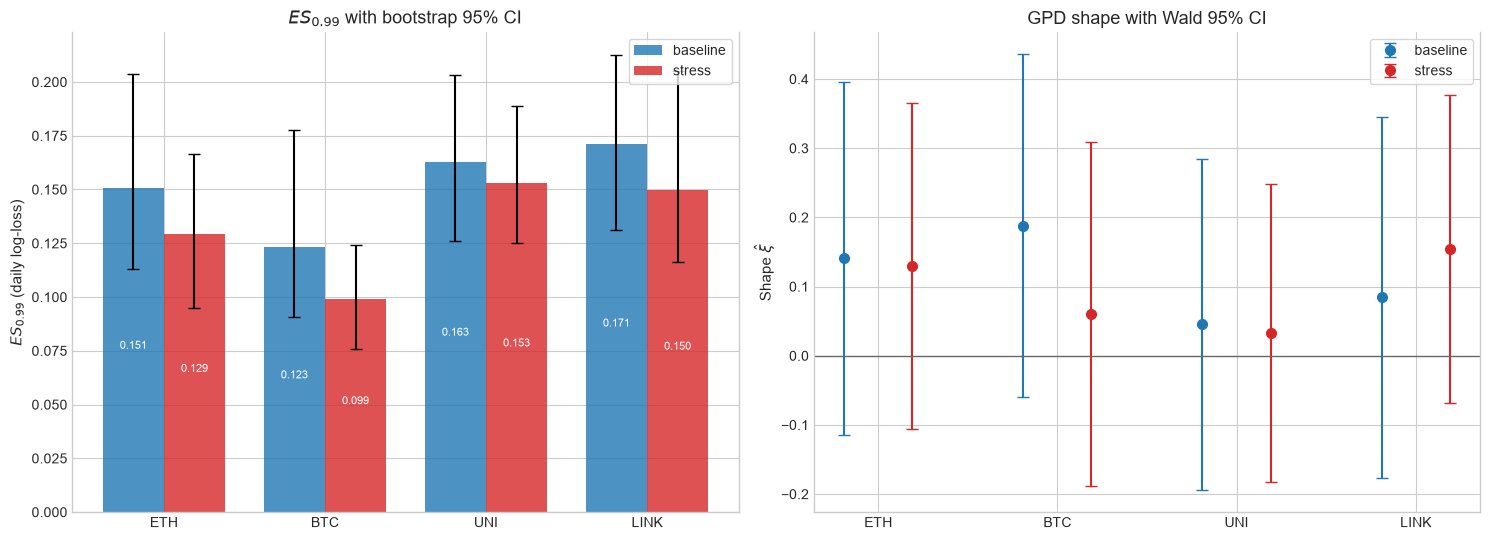

In [88]:
def plot_scenario_comparison() -> None:
    """Grouped comparison of ES (bootstrap CI) and xi (Wald CI) across assets and scenarios."""
    fig, (ax_es, ax_xi) = plt.subplots(1, 2, figsize=(15, 5.5))
    positions = np.arange(len(ASSETS))
    width = 0.38

    for offset, scenario_key in zip((-width / 2, width / 2), SCENARIOS):
        table = evt_results[scenario_key]
        color = SCENARIO_COLORS[scenario_key]
        es_error = np.vstack([table["es"] - table["es_ci_low"], table["es_ci_high"] - table["es"]])
        bars = ax_es.bar(positions + offset, table["es"], width, yerr=es_error, capsize=4, color=color, alpha=0.8, label=scenario_key)
        ax_es.bar_label(bars, labels=[f"{value:.3f}" for value in table["es"]], padding=3, fontsize=8, label_type="center", color="white")

        xi_error = np.vstack([table["xi"] - table["xi_ci_low"], table["xi_ci_high"] - table["xi"]])
        ax_xi.errorbar(positions + offset, table["xi"], yerr=xi_error, fmt="o", capsize=4, color=color, ms=7, label=scenario_key)

    ax_es.set(
        xticks=positions, xticklabels=ASSETS,
        ylabel=f"$ES_{{{CONFIDENCE_LEVEL}}}$ (daily log-loss)",
        title=f"$ES_{{{CONFIDENCE_LEVEL}}}$ with bootstrap {CI_LEVEL:.0%} CI",
    )
    ax_xi.axhline(0.0, color="dimgrey", lw=1)
    ax_xi.set(xticks=positions, xticklabels=ASSETS, ylabel="Shape $\\hat\\xi$", title=f"GPD shape with Wald {CI_LEVEL:.0%} CI")
    ax_es.legend()
    ax_xi.legend()
    fig.tight_layout()
    plt.show()


plot_scenario_comparison()

comparison_df = pd.concat(
    {scenario_key: evt_results[scenario_key][["u_star", "xi", "sigma", "es", "es_ci_low", "es_ci_high"]] for scenario_key in SCENARIOS},
    axis=1,
)
display(comparison_df.style.format(precision=4).set_caption("Side-by-side tail parameters"))

## 15. Methodological notes

- **Units.** $u^*$, $\sigma$, $VaR$ and $ES$ are daily log-losses. Use `es_price_drop` when a multiplicative collateral price shock $P_{t+1} = P_t\,(1 - \text{shock})$ is needed.
- **Unconditional i.i.d. model.** The POT fit treats daily losses as independent. Crypto returns show volatility clustering, so exceedances arrive in clusters; this mainly affects the bootstrap width, which is likely understated. Natural extensions are runs declustering of the exceedances or the conditional GARCH-EVT approach of McNeil & Frey (2000).
- **Small tail samples.** With 30-110 exceedances, $\hat\xi$ carries a standard error of roughly 0.10-0.20, so the sign of $\xi$ can flip between neighbouring thresholds. The stability rule, the LRT p-values and the bootstrap share of $\xi^* > 0$ should be read together, and $u^*$ can be fine-tuned through `THRESHOLD_OVERRIDES`.
- **Threshold-selection uncertainty** is not propagated into the ES interval.

## 16. Manual export of $ES_{0.99}$ collateral shocks (test dump, not for production)

This section is the only part of the notebook that writes to disk. It dumps the parametric $ES_{0.99}$ shock of every collateral asset and market regime to `data/02_interim/notebook_export_evt_shocks_not_for_prod.csv`, in long format with one row per `(scenario, asset)`; scenarios are labelled by their raw-data folder (`baseline_mar2024`, `stress_aug2024`). The file name flags it as a manual test dump of this notebook: it is **not** the official artefact of the automated pipeline and must not be consumed in production.

Exported columns:

- `es_price_shock`: the $ES_{0.99}$ tail event expressed as an arithmetic price decline, $\mathbb{E}[1 - e^{-X} \mid X > VaR_{0.99}]$, i.e. the multiplicative shock $P_{t+1} = P_t\,(1 - \text{shock})$ to apply to the collateral price (Section 11).
- `es_log_loss`, `es_log_loss_ci_low`, `es_log_loss_ci_high`: $ES_{0.99}$ in daily log-loss units with its bootstrap 95% percentile interval (Section 12).
- `var_log_loss`, `u_star`, `threshold_quantile`, `n_exceedances`, `zeta_u`, `xi`, `sigma`, `ad_pvalue`: the POT/GPD fit behind each shock, kept for traceability.
- `n_obs`, `window_start`, `window_end`: number of daily losses and calendar span of the price sample.

Before writing, every row is checked for finite values, $\xi < 1$, the ordering $u^* < VaR_{0.99} < ES_{0.99}$, a well-ordered bootstrap interval, and the bounds $1 - e^{-VaR_{0.99}} \le$ `es_price_shock` $\le 1 - e^{-ES_{0.99}}$ (the upper bound follows from Jensen's inequality, because $1 - e^{-x}$ is concave). After writing, the file is read back and compared exactly with the in-memory table. The file is overwritten on every run, and the objects built in Sections 1-13 are only read, never modified.

In [89]:
INTERIM_DATA_DIR: Path = Path("../data/02_interim")
EVT_SHOCKS_EXPORT_PATH: Path = INTERIM_DATA_DIR / "notebook_export_evt_shocks_not_for_prod.csv"
SHOCK_TOLERANCE: float = 1e-9
SHOCK_KEY_COLUMNS: list[str] = ["scenario", "asset"]
SHOCK_COLUMN_MAP: dict[str, str] = {
    "confidence_level": "confidence_level",
    "es_price_drop": "es_price_shock",
    "es": "es_log_loss",
    "es_ci_low": "es_log_loss_ci_low",
    "es_ci_high": "es_log_loss_ci_high",
    "var": "var_log_loss",
    "u_star": "u_star",
    "threshold_quantile": "threshold_quantile",
    "n_exceedances": "n_exceedances",
    "zeta_u": "zeta_u",
    "xi": "xi",
    "sigma": "sigma",
    "ad_pvalue": "ad_pvalue",
}


def build_shock_export_table(
    results: dict[str, pd.DataFrame],
    prices: dict[str, dict[str, pd.Series]],
    loss_series: dict[str, dict[str, pd.Series]],
) -> pd.DataFrame:
    """Stack the ES_p collateral shocks of every scenario into one long table keyed by (scenario, asset).

    Args:
        results: Consolidated EVT tables of Section 13, keyed by scenario and indexed by asset.
        prices: Daily close prices of Section 2, used to record the sample window.
        loss_series: Daily log-losses of Section 3, used to record the sample size.

    Returns:
        One row per (scenario, asset), with scenarios labelled by their raw-data folder name.

    Raises:
        KeyError: If a scenario, a required column or an asset is missing from the inputs.
    """
    blocks: list[pd.DataFrame] = []
    for scenario_folder in SCENARIO_DIRS:
        key = SCENARIO_KEY[scenario_folder]
        if key not in results or key not in prices or key not in loss_series:
            raise KeyError(f"EVT inputs missing for scenario '{key}'")
        scenario_table = results[key]
        missing_columns = sorted(set(SHOCK_COLUMN_MAP) - set(scenario_table.columns))
        if missing_columns:
            raise KeyError(f"[{key}] EVT results are missing columns: {missing_columns}")
        missing_assets = sorted(set(ASSETS) - set(scenario_table.index))
        if missing_assets:
            raise KeyError(f"[{key}] EVT results are missing assets: {missing_assets}")

        block = scenario_table.loc[ASSETS, list(SHOCK_COLUMN_MAP)].rename(columns=SHOCK_COLUMN_MAP)
        block = block.rename_axis("asset").reset_index()
        block.insert(0, "scenario", scenario_folder)
        block["n_obs"] = [loss_series[key][name].size for name in ASSETS]
        block["window_start"] = [prices[key][name].index.min().strftime("%Y-%m-%d") for name in ASSETS]
        block["window_end"] = [prices[key][name].index.max().strftime("%Y-%m-%d") for name in ASSETS]
        blocks.append(block)
    return pd.concat(blocks, ignore_index=True)


def _failing_keys(shocks: pd.DataFrame, mask: pd.Series | np.ndarray) -> list[tuple[str, str]]:
    """Return the (scenario, asset) keys of the rows selected by a boolean mask."""
    return list(shocks.loc[mask, SHOCK_KEY_COLUMNS].itertuples(index=False, name=None))


def validate_shock_table(shocks: pd.DataFrame, tolerance: float = SHOCK_TOLERANCE) -> None:
    """Check that every exported shock is finite and consistent with the POT/GPD model.

    Raises:
        ValueError: If rows are missing or duplicated, values are non-finite or a consistency rule fails.
    """
    expected_rows = len(SCENARIO_DIRS) * len(ASSETS)
    if len(shocks) != expected_rows:
        raise ValueError(f"Expected {expected_rows} shock rows, found {len(shocks)}")
    if shocks.duplicated(SHOCK_KEY_COLUMNS).any():
        raise ValueError("Shock table contains duplicated (scenario, asset) keys")

    numeric_columns = list(SHOCK_COLUMN_MAP.values()) + ["n_obs"]
    is_finite = np.isfinite(shocks[numeric_columns].to_numpy(dtype=float)).all(axis=1)
    if not is_finite.all():
        raise ValueError(f"Non-finite shock parameters for: {_failing_keys(shocks, ~is_finite)}")

    rules: dict[str, pd.Series] = {
        f"confidence_level == {CONFIDENCE_LEVEL}": pd.Series(
            np.isclose(shocks["confidence_level"], CONFIDENCE_LEVEL), index=shocks.index
        ),
        "xi < 1 (finite ES)": shocks["xi"] < 1.0,
        "u* < VaR < ES": (shocks["u_star"] < shocks["var_log_loss"]) & (shocks["var_log_loss"] < shocks["es_log_loss"]),
        "ES CI low <= ES CI high": shocks["es_log_loss_ci_low"] <= shocks["es_log_loss_ci_high"],
        "0 < price shock < 1": shocks["es_price_shock"].between(0.0, 1.0, inclusive="neither"),
        "1 - exp(-VaR) <= price shock <= 1 - exp(-ES)": shocks["es_price_shock"].between(
            -np.expm1(-shocks["var_log_loss"]) - tolerance, -np.expm1(-shocks["es_log_loss"]) + tolerance
        ),
    }
    for rule, passed in rules.items():
        if not passed.all():
            raise ValueError(f"Shock validation failed ({rule}) for: {_failing_keys(shocks, ~passed)}")

    outside_ci = ~shocks["es_log_loss"].between(shocks["es_log_loss_ci_low"], shocks["es_log_loss_ci_high"])
    for scenario_label, asset_label in _failing_keys(shocks, outside_ci):
        logger.warning("[%s] %s: ES point estimate lies outside its bootstrap CI", scenario_label, asset_label)


def export_shock_table(shocks: pd.DataFrame, output_path: Path) -> pd.DataFrame:
    """Write the shock table to CSV and verify an exact round trip.

    Returns:
        The table as reloaded from disk.

    Raises:
        OSError: If the file cannot be written or read back.
        ValueError: If the reloaded file differs from the in-memory table.
    """
    try:
        output_path.parent.mkdir(parents=True, exist_ok=True)
        if output_path.exists():
            logger.info("Overwriting existing notebook dump %s", output_path.resolve())
        shocks.to_csv(output_path, index=False)
        reloaded = pd.read_csv(output_path, float_precision="round_trip")
    except OSError as exc:
        raise OSError(f"Failed to write or reload {output_path.resolve()}: {exc}") from exc

    try:
        pd.testing.assert_frame_equal(reloaded, shocks, check_exact=True)
    except AssertionError as exc:
        raise ValueError(f"Round-trip verification failed for {output_path.resolve()}: {exc}") from exc
    return reloaded


evt_shocks_export_df = build_shock_export_table(evt_results, close_prices, losses)
validate_shock_table(evt_shocks_export_df)
evt_shocks_reloaded_df = export_shock_table(evt_shocks_export_df, EVT_SHOCKS_EXPORT_PATH)
logger.info(
    "ES %s collateral shocks written to %s (%d rows; manual notebook dump, NOT for production)",
    CONFIDENCE_LEVEL, EVT_SHOCKS_EXPORT_PATH.resolve(), len(evt_shocks_reloaded_df),
)

display(
    evt_shocks_reloaded_df.set_index(SHOCK_KEY_COLUMNS)
    .style.format(precision=4)
    .format({"es_price_shock": "{:.2%}", "confidence_level": "{:.2f}", "threshold_quantile": "{:.3f}"})
    .set_caption(f"ES {CONFIDENCE_LEVEL} collateral shocks reloaded from {EVT_SHOCKS_EXPORT_PATH.name}")
)

INFO | evt_gpd | Overwriting existing notebook dump C:\Users\facun\Repos\Tesina\data\02_interim\notebook_export_evt_shocks_not_for_prod.csv
INFO | evt_gpd | ES 0.99 collateral shocks written to C:\Users\facun\Repos\Tesina\data\02_interim\notebook_export_evt_shocks_not_for_prod.csv (8 rows; manual notebook dump, NOT for production)
